# QDC 2026 challenge: Trade Circuits for Shots

In QAOA for a constrained problem, the constraint is the expensive part of the circuit: a penalty term couples every pair of qubits, and a constraint-preserving XY mixer also needs two-qubit gates on every pair of qubits (paper Sec. IV). In May 2026, A. Carrera Vazquez, D. J. Egger and S. Woerner showed that both can be replaced by an *ensemble* of much simpler circuits, using a Fourier-based **linear combination of unitaries (LCU)**, and ran the method on a 106-qubit problem on IBM hardware ([arXiv:2605.18985](https://arxiv.org/abs/2605.18985)). The circuits get shorter; the price is paid in measurement shots. That trade is the subject of this challenge.

You will build the method in Qiskit, run it on a real backend, and then try to improve on it.

**What's graded**

| Part | What you do | Points |
|---|---|---|
| 1 | Build the method in Qiskit on a 12-qubit instance: circuit, LCU ensemble, transpilation, a run on your backend, post-processing (Exercises 1a to 1d) | 20 |
| 2 | Campaign on your 106-qubit instance: four exercises (Exercises 2a to 2d, 10 points) and the best job score you can reach (Exercise 2e, 55 points) | 65 |
| 3 | Frontier round: three controlled experiments that go beyond the paper, one per axis: circuit depth, partial LCU, training policy (Exercises 3d, 3l and 3t) | 15 |

**References**
- The paper, [arXiv:2605.18985](https://arxiv.org/abs/2605.18985). Sections II B and III explain the LCU, Section V the QAOA circuits, Section VI the experiments. Fig. 3 is the circuit you build in Part 1.
- The authors' code: [https://github.com/stefan-woerner/fourier-lcu](https://github.com/stefan-woerner/fourier-lcu).
- Qiskit documentation: [Qiskit patterns](https://quantum.cloud.ibm.com/docs/guides/intro-to-patterns), [transpilation](https://quantum.cloud.ibm.com/docs/guides/transpile), [primitives and PUBs](https://quantum.cloud.ibm.com/docs/guides/primitive-input-output), [execution modes](https://quantum.cloud.ibm.com/docs/guides/execution-modes).
- Error suppression and error mitigation in IBM's documentation (Part 2, Step 5, lists what each tool can do for a score): [techniques](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques), [noise management with the Sampler](https://quantum.cloud.ibm.com/docs/guides/sampler-noise-management), [Sampler options and their compatibility](https://quantum.cloud.ibm.com/docs/guides/sampler-options), [noise management with the Estimator](https://quantum.cloud.ibm.com/docs/guides/estimator-noise-management), [`PadDynamicalDecoupling`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.transpiler.passes.PadDynamicalDecoupling), [postselection](https://quantum.cloud.ibm.com/docs/guides/post-selection), [Qiskit addons](https://quantum.cloud.ibm.com/docs/guides/addons), [M3](https://qiskit.github.io/qiskit-addon-mthree/), [`qiskit-mitigation`](https://quantum.cloud.ibm.com/docs/addons/qiskit-mitigation). This notebook uses the client-side `Sampler` of `qiskit_ibm_runtime.executor_sampler` (qiskit-ibm-runtime 0.50 and later), as IBM's current examples do: it runs as `Executor` jobs, and its options are the ones these pages describe. Older examples import `SamplerV2` from `qiskit_ibm_runtime`, the deprecated server-side sampler; the grading functions read the counts of both kinds of job.
- The QDC pre-work packet ("QDC Challenges Pre-Work Packet", distributed with the event materials) lists IBM's tools for mapping, transpilation, execution, error mitigation and post-processing with links to their documentation. The tools table of Part 2, Step 5 says which of them can change a score in this challenge.
- [`qiskit-addon-opt-mapper`](https://github.com/Qiskit/qiskit-addon-opt-mapper) maps the problem to operators in Part 1. A related package, [`qopt-best-practices`](https://github.com/qiskit-community/qopt-best-practices), provides transpiler passes for QAOA on hardware, such as swap strategies for dense problems (install from GitHub: `pip install git+https://github.com/qiskit-community/qopt-best-practices`).

**Rules**

- AI assistants are allowed everywhere. Classical computation may be used to choose circuit *parameters*.
- Scored samples must come from quantum circuits that implement the assigned cost function with the circuit families of this challenge (the basis circuit of Fig. 3 at any depth, its LCU ensembles, and the XY-mixer basis circuit of Fig. 5): a classical solver may not construct or select output bitstrings.
- Error suppression (dynamical decoupling, twirling, circuit choices) changes the shots you get and is allowed. The grader scores a sample of the raw shots of the job you grade, so post-processing of bitstrings does not change a score; error mitigation may be used when you estimate expectation values to choose parameters, but the extra jobs it needs cannot improve a score and still use QPU time. Use IBM's Qiskit packages for error suppression and error mitigation, not third-party libraries.
- Hardware results are self-reported: the grading functions read your jobs on your own machine, and the organizers may audit the job ids after the event.
- The leading submissions are reviewed, and the top three teams present their method.

## Time plan

This notebook takes about six and a half hours of work, spread over the event:

| Part | Time | What you do |
|---|---|---|
| 0 | 20 min | setup, scoring rules, the problem |
| 1 | 2.5 h | four exercises and one practice job on your backend |
| 2 | 2.5 h | the baseline job, Exercises 2a to 2d, further jobs for Exercise 2e |
| 3 | 1 h | the example of Exercise 3d and one experiment of your own |

The rest is waiting for your jobs in the queue. You write code in the cells of Exercises 1a to 1d and 2a to 2d. Every exercise has a task box that says what you write, what it takes and returns and how the grader scores it, and a cell whose grading call sends your answer to the grading server and prints its answer; Exercises 1a to 2d also have three hints below the box. The other cells of Parts 2 and 3 run as given. Your own jobs and experiments go in new cells; the template in Part 2 lists the steps.

Before you start, install the grader package (`pip install -U qc-grader`) and set `TEAM_NAME`, your team's name, in the team cell of Part 0.

## Part 0: Setup

The next cell connects to your IBM Quantum account, selects your assigned backend and loads your 106-qubit instance; the cells after it import the grading functions and join your team.

- **Grading.** `from qc_grader.challenges.qdc_2026 import ...` imports one grading function per exercise, `grade_lab_tcfs_ex1a` to `grade_lab_tcfs_ex3t`, with `check_progress` and `join_team`; the package is installed with `pip install -U qc-grader`. QDC 2026 is played in teams: set `TEAM_NAME` in the team cell below the import (the cell that calls `join_team`) and run it before the first grading call.
- **Account and backend.** `QiskitRuntimeService()` uses your default saved account; if you saved the event account under a name, set the environment variable `QDC_ACCOUNT` to that name or pass `name="..."`. Replace `ibm_phoenix` with your assigned backend.
- **Your instance.** At the event you receive your instance as a handout file: set `HANDOUT` to its path. `hw.load_handout` returns the instance and its layout on the backend; the instance carries the id that the grading functions send, `inst106.instance_id`. Without a handout the notebook uses its demo instance (id `demo106`), which is for practice and is not an event instance.
- **The sampler.** The notebook uses the client-side `Sampler` of `qiskit_ibm_runtime.executor_sampler`, introduced in qiskit-ibm-runtime 0.50: the same PUBs, options and results as the deprecated server-side `SamplerV2`, with the pre- and post-processing done on your machine and the execution delegated to IBM's `Executor` primitive. Its jobs appear as `executor` jobs on IBM Quantum Platform (`job.primitive_id`), and all PUBs of one job must have the same number of shots.

The challenge kit is the local `tcfs` package:

| module | contents |
|---|---|
| `tcfs.instances` | the problem instance: graph, `k`, penalty factor `lam` |
| `tcfs.circuits`, `tcfs.exact` | reference circuits and an exact 12-qubit engine |
| `tcfs.hardware` (`hw`) | the 106-qubit circuit builder, parameter transfer, cost estimates, handout files |
| `tcfs.policy` | a training toolbox for small instances |
| `tcfs.jobs` | `run_once`: a job submitted once per tag and returned again when a cell runs again |
| `tcfs.event` | the training instance, the paper's angles, the demo instance and the QPU-time estimate of a job |
| `tcfs.nb` | the tables and plots of this notebook |

In [ ]:
import os

import numpy as np
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.executor_sampler import Sampler           # the client-side sampler (qiskit-ibm-runtime 0.50 and later)

from tcfs import event, jobs, nb, hardware as hw

service = QiskitRuntimeService(name=os.getenv("QDC_ACCOUNT"))    # None: your default saved account
backend = service.backend("ibm_phoenix")                          # your assigned backend
HANDOUT = None                                                    # at the event: the path of your handout file
inst106, layout = hw.load_handout(HANDOUT) if HANDOUT else event.demo_instance()[:2]
print(f"backend {backend.name}; instance {inst106.instance_id}: n = {inst106.n}, k = {inst106.k}")

Grading goes through the challenge client, and QDC 2026 is played in teams: answers are only graded once you have joined your team. Set `TEAM_NAME` below and run the cell before you grade anything. Every member must type the team name exactly the same way (capitals and spaces count). It can have letters, digits, spaces, hyphens and underscores, up to 35 characters. Your team's best score on each exercise counts, so you can resubmit.

In [ ]:
from qc_grader.challenges.qdc_2026 import (
    check_progress, join_team,
    grade_lab_tcfs_ex1a, grade_lab_tcfs_ex1b, grade_lab_tcfs_ex1c, grade_lab_tcfs_ex1d,
    grade_lab_tcfs_ex2a, grade_lab_tcfs_ex2b, grade_lab_tcfs_ex2c, grade_lab_tcfs_ex2d,
    grade_lab_tcfs_ex2e, grade_lab_tcfs_ex3d, grade_lab_tcfs_ex3l, grade_lab_tcfs_ex3t,
)

In [ ]:
TEAM_NAME = ""  # YOUR TEAM NAME, the same for every member

if TEAM_NAME:
    join_team(TEAM_NAME)
else:
    print("Set TEAM_NAME to your team's name and run this cell again: answers are only graded for a team.")

### How the challenge is scored

| | |
|---|---|
| **Grading** | every exercise is graded by one call, `grade_lab_tcfs_<exercise>(...)`, in the cell after its code: the grading function packs your answer, sends it to the grading server, which validates it, and prints the result. You can grade an exercise again as often as you like: for each exercise your best score counts, so a later, worse attempt never lowers it. `check_progress()` shows your scores |
| **Points** | Part 1: Exercises 1a to 1d, 20 points. Part 2: Exercises 2a to 2d, 10 points, and Exercise 2e, your best job on your 106-qubit instance, 55 points. Part 3: Exercises 3d, 3l and 3t, 5 points each. Total 100 |
| **Your jobs** | you run your own `Sampler` jobs on your assigned backend. A grading function that takes a job reads it on your machine and sends the job id, the backend, the QPU usage, the number of shots and a sample of 4,096 of its shots, drawn with a fixed seed; the grading server never contacts IBM Quantum. These hardware numbers are self-reported: the organizers may audit the job ids after the event, so grade only your own jobs, run on your instance and your assigned backend |
| **Your instance** | the grading functions send the id of your instance (`inst106.instance_id`); the grading server holds the instance, its optimum OPT and its baseline $B$ under that id |
| **QPU time** | your IBM Quantum account has 30 minutes of QPU time for the event, enforced by IBM; the grader does not track it. A one-layer job of $2^{15}$ shots on the 106-qubit instance uses about 3.4 s, the practice job of Exercise 1d about 5 s |
| **Execution mode** | job mode or Batch. A Session uses QPU time for as long as it is open |
| **Bonus** | design-review stamp: +2 points; presentation by the top three teams: +3 points. The organizers award both outside the grader; time and place are announced at the event (bring your plan of Exercise 2d and the hypotheses of your Part 3 experiments) |
| **Ties** | equal totals are ordered by the time at which a team's best submissions were all in |

**How the grader answers.** Each grading call prints `Grading your answer. Please wait...` and then the grader's answer. A passing answer prints the grader's message, which begins with `Congratulations!` and may add what was measured, and then the line `You scored <points> on this exercise.` A failing answer prints `Not quite!`, the grader's message — what it observed, what it expected and where in the notebook to look — and `Please review your answer and try again.`; an answer that earns part of the points has the line `You scored <points> on this exercise.` before the last line. A known mistake, such as the wrong sign of a gate angle or the wrong bit order, is named in the message. Before anything is sent, the grading function checks what you pass to it: an argument of the wrong kind stops the cell with an error whose message says what to pass, and nothing is graded. A grading function that takes one of your functions calls it on your machine, on fixed inputs, and sends what it returns: your code runs only on your machine, never on the grading server. Only whether an answer passed and its score are stored, not the answer itself.

### The problem: densest-k-subgraph

From a graph with $n$ nodes, choose exactly $k$ nodes so that as many edges as possible have both end points in the selection:

$$\max_{x\in\{0,1\}^n}\; f(x) = \sum_{(i,j)\in E} w_{ij}\,x_i x_j \qquad\text{subject to}\qquad \sum_{i} x_i = k .$$

Here $E$ is the set of edges, $x_i = 1$ means node $i$ is selected, and $w_{ij} = 1$ for the unweighted graphs of this challenge. The constraint is handled with a penalty on the Hamming weight $W(x) = \sum_{i=0}^{n-1} x_i$:

$$f_\lambda(x) = f(x) - \lambda\,\big(W(x)-k\big)^2, \qquad \lambda = 1 + \max_i \sum_{j:(i,j)\in E} |w_{ij}| .$$

With this $\lambda$ a constraint violation never improves the value: adding or removing one node changes $f$ by at most $\lambda - 1$, while each step of $W$ away from $k$ costs at least $\lambda$ (paper Sec. VI A). The maximum of $f_\lambda$ is therefore the optimum of the constrained problem. All scores in this challenge are computed from $f_\lambda$.

Part 1 uses the 12-node, 3-regular instance of the paper ($k = 4$, 18 edges, $\lambda = 4$). Its optimum is 4 edges:

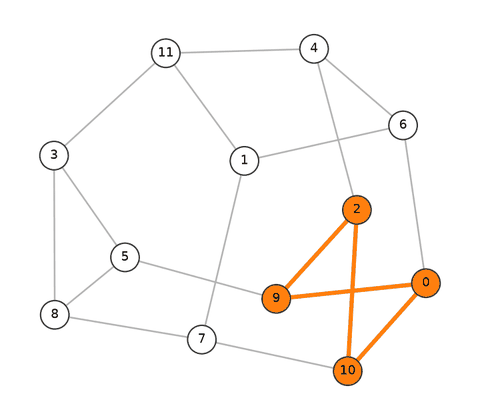

*The training instance, the graph of paper Fig. 2. One optimal selection is highlighted (paper Fig. 2 highlights another, {3, 5, 7, 8}); each contains 4 of the 18 edges.*

In [ ]:
inst = event.training_instance()      # the paper's 12-node instance
print(f"n = {inst.n}, edges = {len(inst.edges)}, k = {inst.k}, lambda = {inst.lam:.0f}")

## Part 1: Build the method in Qiskit (20 points)

Part 1 builds the method on the 12-qubit instance. At this size every step can be checked exactly against a statevector; at 106 qubits there is no statevector to check against, so mistakes must be found here. The exercises follow the four steps of a Qiskit pattern:

| Step | Exercise | You write |
|---|---|---|
| Map | 1a | the QAOA basis circuit as a parametrized `QuantumCircuit` |
| Map | 1b | the Fourier LCU: the branch angles, coefficients, weights and sampling overhead |
| Optimize | 1c | the ISA circuit for your backend |
| Execute, post-process | 1d | the scoring of counts, `evaluate_counts` and `cvar`; the job cell that runs on the QPU is given |

**The circuit.** Depth-1 QAOA for $f_\lambda$, with cost angle $\gamma$ and mixer angle $\beta$, prepares

$$|\psi(\gamma,\beta)\rangle = M(\beta)\; e^{-i\gamma H_2}\; e^{-i\gamma H_1}\;|\psi_0\rangle ,$$

where $H_1$ is the objective $f$ and $H_2 = -\lambda (W-k)^2$ the penalty, both as diagonal operators, $|\psi_0\rangle$ is the initial state and $M(\beta)$ the mixer. Read it right to left, like the circuit:
- the warm start $|\psi_0\rangle$ prepares every qubit on its own, with one single-qubit gate;
- the cost layer $e^{-i\gamma H_1}$ is local to the graph and cheap: one two-qubit gate per edge;
- the constraint layer $e^{-i\gamma H_2}$ is the expensive part: one two-qubit gate for *every pair* of qubits, 66 at $n = 12$ and 5,565 at $n = 106$;
- the mixer $M(\beta)$ acts on single qubits only.

The method of the paper removes the constraint layer.

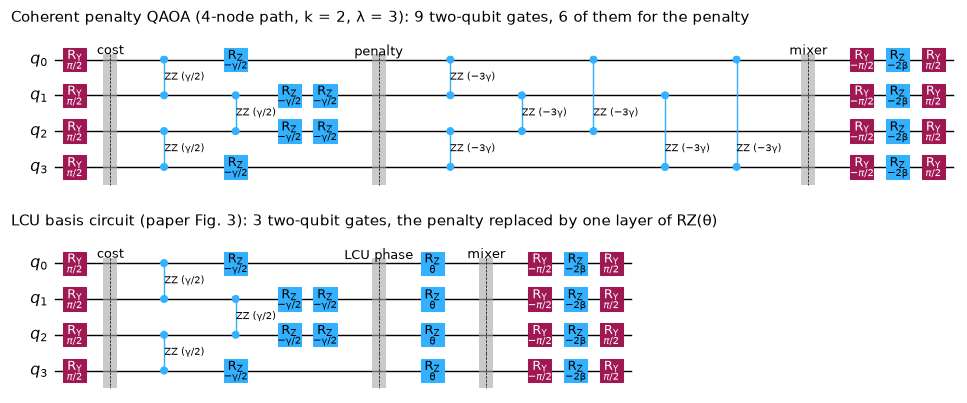

*The coherent circuit (top) and the basis circuit (bottom) on a 4-node example: one layer of `rz(theta)` takes the place of the penalty block, which acts on every pair of qubits.*

### Map the problem to operators

`qiskit-addon-opt-mapper` models the optimization problem and converts it to an Ising Hamiltonian. The next cell builds the problem twice: the objective alone, and the objective with the constraint turned into the quadratic penalty.

In [ ]:
from qiskit_addon_opt_mapper import OptimizationProblem
from qiskit_addon_opt_mapper.converters import EqualityToPenalty
from qiskit_addon_opt_mapper.translators import to_ising

def dks_problem(inst, constrained):
    problem = OptimizationProblem("densest-k-subgraph")
    for i in range(inst.n):
        problem.binary_var(f"x{i}")
    problem.maximize(quadratic={(f"x{i}", f"x{j}"): w for i, j, w in inst.edges})
    if constrained:
        problem.linear_constraint({f"x{i}": 1 for i in range(inst.n)}, "==", inst.k, name="cardinality")
    return problem

print(dks_problem(inst, constrained=True).prettyprint())

ising_objective, _ = to_ising(dks_problem(inst, constrained=False))
ising_penalized, _ = to_ising(EqualityToPenalty(penalty=inst.lam).convert(dks_problem(inst, constrained=True)))
cost_op = -ising_objective          # to_ising returns the operator to *minimize*; H1 = f is its negative (up to a constant)
nb.operator_summary(objective=ising_objective, penalized=ising_penalized)

### Exercise 1a: The basis circuit (5 points)

The circuit you build is Fig. 3 of the paper. It has four layers, all acting on $n$ qubits:

| Layer | Operator | Gates |
|---|---|---|
| 1. Initial state | $\lvert\psi_0\rangle = \big(\sqrt{1-k/n}\,\lvert 0\rangle + \sqrt{k/n}\,\lvert 1\rangle\big)^{\otimes n}$ | `ry(theta_init)` on every qubit, $\theta_{\rm init} = 2\arcsin\sqrt{k/n}$ (`inst.theta_init`) |
| 2. Cost layer | $e^{-i\gamma H_1}$, $H_1 = \sum_{(i,j)\in E} w_{ij}\,x_i x_j$ | for every edge $(i, j, w)$: `rzz(gamma*w/2)` on $(i,j)$, and `rz(-gamma*w/2)` on $i$ and on $j$ |
| 3. LCU phase layer | $V(\theta) = e^{i\theta W}$ | `rz(theta)` on every qubit |
| 4. Mixer | $M(\beta) = \big[R_Y(\theta_{\rm init})\,R_Z(-2\beta)\,R_Y(-\theta_{\rm init})\big]^{\otimes n}$ | on every qubit, in circuit order: `ry(-theta_init)`, `rz(-2*beta)`, `ry(theta_init)` |

**Initial state.** Every qubit is a coin that shows 1 with probability $k/n$, so the expected Hamming weight is already $k$. The uniform superposition would flip fair coins instead: the mean weight would be $n/2$, and exactly $k$ ones would be rare (about 1 in 6,000 at $n = 106$, $k = 35$). With the biased coin, $P(W = k)$ is 23.8 % at $n = 12$, $k = 4$, and still 8.2 % at $n = 106$, $k = 35$. This product state is the warm start of the paper (Sec. VI).

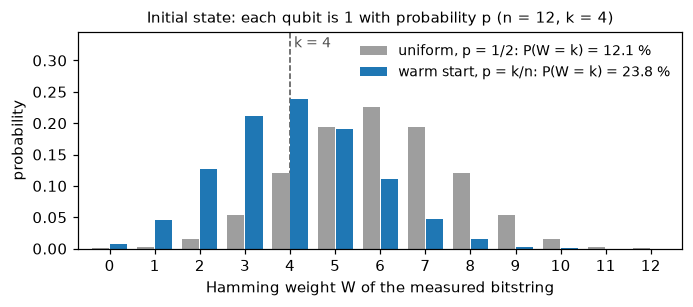

**Cost layer.** With $x_i = (1 - Z_i)/2$, $x_i x_j = (1 - Z_i - Z_j + Z_i Z_j)/4$. The $Z_iZ_j$ term is an `rzz`, the single $Z$ terms are `rz`, the constant is a global phase. Alternatively, `PauliEvolutionGate(cost_op, time=gamma)` (from `qiskit.circuit.library`) builds the same layer from the operator of the previous step, up to a global phase.

**LCU phase layer.** $R_Z(\theta)^{\otimes n}$ multiplies $\lvert x\rangle$ by $e^{i\theta W(x)}$, up to a global phase. This single-qubit layer stands in for the whole penalty block; Exercise 1b shows how.

**Mixer.** It rotates each qubit about the axis of its initial state, so $\lvert\psi_0\rangle$ is its fixed point (the warm-start mixer of paper Fig. 3). Fig. 3 writes the middle gate as $R_Z(\beta)$; this notebook writes it as $R_Z(-2\beta)$, a rescaled $\beta$. Use `rz(-2*beta)`: the grader and the kit's angles follow this convention. The mixer acts on single qubits only, which is why one layer of the circuit can be evaluated classically even at 106 qubits; Part 2 uses this.

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 1a).</b>
<ul>
<li><b>Write:</b> the four layers above in <code>basis_circuit(inst)</code>, in the next code cell, under the numbered comments between <code>### 1. initial state</code> and the closing <code>###</code>. The three parameters, <code>qc = QuantumCircuit(n)</code>, the final <code>qc.measure_all()</code> and <code>return qc</code> are given.</li>
<li><b>Input:</b> <code>inst</code>, the problem instance, with the fields <code>n</code>, <code>k</code>, <code>lam</code>, <code>edges</code> (tuples <code>(i, j, w)</code>) and <code>theta_init</code>. The grading function calls your function with the 12-node training instance; the last line of the cell calls it again on a 4-node path.</li>
<li><b>Return:</b> one <code>QuantumCircuit</code> on exactly <code>inst.n</code> qubits, with the four layers above. Its free parameters are exactly <code>Parameter("gamma")</code>, <code>Parameter("theta")</code> and <code>Parameter("beta")</code>: these names and no others. Every qubit is measured once, into one register of <code>inst.n</code> bits, bit i for node i. Keep the given <code>measure_all()</code>: its register is named <code>meas</code>, and the cell after the job cell of Exercise 1d reads <code>result[0].data.meas</code>. The grader accepts any register name, so a circuit built as <code>QuantumCircuit(n, n)</code> and measured with <code>qc.measure(range(n), range(n))</code>, whose register is named <code>c</code>, passes here, but that cell then stops with an <code>AttributeError</code>, after the job has run on the QPU. With the given <code>measure_all()</code> kept, <code>QuantumCircuit(n, n)</code> fails here, because the circuit then has two registers.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex1a(basis_circuit, inst)</code>: your function itself, not a circuit, and the training instance. The grading function calls <code>basis_circuit(inst)</code> on your machine and sends the circuit it returns.</li>
<li><b>The grader checks:</b> that the circuit has 12 qubits, the free parameters <code>gamma</code>, <code>theta</code> and <code>beta</code> and no others, and one register in which every qubit is measured once. It binds three fixed parameter sets (γ, θ, β), the same on every run, and compares the measured distribution with the exact statevector reference, to within 1e-9 in every probability. It then decomposes composite gates such as <code>PauliEvolutionGate</code> and checks that every two-qubit gate acts on an edge of the graph and that every edge has one. A known mistake, such as <code>rz(beta)</code> in the mixer, is named in the message.</li>
<li><b>Points:</b> 5, all or nothing. You can grade again; the best score counts.</li>
</ul></div>

<details><summary>Hint 1</summary>

Build the circuit layer by layer. Each layer is a loop over the qubits or over `inst.edges`, and a gate angle may be an expression of a `Parameter`, such as `gamma * w / 2`. Most gate methods also accept a range of qubits: `qc.ry(t0, range(n))` puts one `ry` on every qubit.

</details>

<details><summary>Hint 2</summary>

With `t0 = inst.theta_init` and every qubit $q = 0, \dots, n-1$: layer 1 is `ry(t0)` on $q$. Layer 2 is, for every tuple `(i, j, w)` in `inst.edges`, `rzz(gamma * w / 2)` on qubits $i$ and $j$, then `rz(-gamma * w / 2)` on $i$ and on $j$. Layer 3 is `rz(theta)` on $q$. Layer 4 is `ry(-t0)`, `rz(-2 * beta)` and `ry(t0)` on $q$, in this order. When the grader recognizes a mistake, its message names it; the most common are the sign of the `rz` terms in layer 2, the factor 1/2 in the `rzz` angle and the order of the mixer gates.

</details>

<details><summary>Hint 3</summary>

Near-code for the four regions:

```python
qc.ry(t0, range(n))                    # 1. initial state
for i, j, w in inst.edges:             # 2. cost layer
    qc.rzz(gamma * w / 2, i, j)
    qc.rz(-gamma * w / 2, i)
    qc.rz(-gamma * w / 2, j)
qc.rz(theta, range(n))                 # 3. LCU phase layer
qc.ry(-t0, range(n))                   # 4. mixer
qc.rz(-2 * beta, range(n))
qc.ry(t0, range(n))
```

</details>

In [ ]:
def basis_circuit(inst):
    """The LCU basis circuit of paper Fig. 3, with parameters gamma, theta, beta.

    inst: the problem instance (inst.n qubits, inst.edges, inst.theta_init).
    Returns: a QuantumCircuit on inst.n qubits with the free parameters gamma, theta and beta,
    measured by measure_all() into one register named meas.
    """
    gamma, theta, beta = Parameter("gamma"), Parameter("theta"), Parameter("beta")
    n, t0 = inst.n, inst.theta_init
    qc = QuantumCircuit(n)
    ### 1. initial state
    ### 2. cost layer
    ### 3. LCU phase layer
    ### 4. mixer
    raise NotImplementedError("Exercise 1a: write the four layers under the numbered comments, then delete this line")
    ###
    qc.measure_all()
    return qc

nb.draw_example(basis_circuit)      # the same function on a 4-node path, where the four layers are legible

In [ ]:
grade_lab_tcfs_ex1a(basis_circuit, inst)

### Exercise 1b: The Fourier LCU of the penalty (5 points)

The basis circuit contains no penalty. The missing block is $e^{-i\gamma H_2}$ with $H_2 = -\lambda (W-k)^2$.

**A linear combination of unitaries without an ancilla** (paper Sec. II B). The unitary you want is expensive, but it is a weighted sum of unitaries you can afford, $U = \sum_b c_b V_b$. Implementing the sum coherently needs an ancilla qubit and controlled operations. An optimization run does not need the output state, only good bitstrings often enough: so run branch $b$ with probability

$$q_b = \frac{|c_b|}{\lVert c\rVert_1}, \qquad \lVert c\rVert_1 = \sum_{b}|c_b| ,$$

and pool the shots. For every bitstring $x$ the pooled distribution $\tilde p$ satisfies

$$\tilde p(x) \;\ge\; \frac{p(x)}{\Gamma}, \qquad \Gamma = \lVert c\rVert_1^{\,2} ,$$

where $p$ is the distribution of the circuit that contains $U$. The reason fits in one line: with $a_b$ the amplitude of $x$ in branch $b$, the Cauchy–Schwarz inequality gives $\big|\sum_b c_b a_b\big|^2 \le \big(\sum_b |c_b|\big)\big(\sum_b |c_b|\,|a_b|^2\big)$, which is $p(x) \le \Gamma\,\tilde p(x)$. No bitstring gets lost: whatever the expensive circuit finds, the ensemble finds at least $1/\Gamma$ as often. $\Gamma$ is the **sampling overhead**, the exchange rate between circuits and shots.

**Where the decomposition comes from** (paper Sec. III). The penalty block is diagonal and depends on the bitstring only through its Hamming weight $W$, which takes the $n+1$ values $0,\dots,n$. Write its diagonal entry as a function of the weight:

$$u(W) = e^{+i\gamma\lambda\,(W-k)^2}, \qquad W = 0,\dots,n .$$

A function on $n+1$ points is a sum of $n+1$ pure tones: its discrete Fourier transform. With the angles $\theta_b = 2\pi b/(n+1)$, $b = 0,\dots,n$:

$$u(W) = \sum_{b=0}^{n} c_b\, e^{i\theta_b W}, \qquad c_b = \frac{1}{n+1}\sum_{W=0}^{n} u(W)\, e^{-i\theta_b W} .$$

Each tone is one layer of `rz` gates: $e^{i\theta_b W}$ is the LCU phase layer $V(\theta_b)$ of Exercise 1a. So the penalty block is a **linear combination of $n+1$ unitaries**, each one layer of single-qubit gates:

$$e^{-i\gamma H_2} = \sum_{b=0}^{n} c_b\, V(\theta_b) .$$

The all-to-all block becomes $n+1$ single-qubit layers and one call to `np.fft.fft`. Because $|u(W)| = 1$, Parseval's identity gives $\lVert c\rVert_2 = \big(\sum_{b=0}^{n}|c_b|^2\big)^{1/2} = 1$. With $\lVert c\rVert_1 \le \sqrt{n+1}\,\lVert c\rVert_2$, this gives $\Gamma \le n+1$ (paper Sec. III): a linear overhead for removing a quadratic gate count.

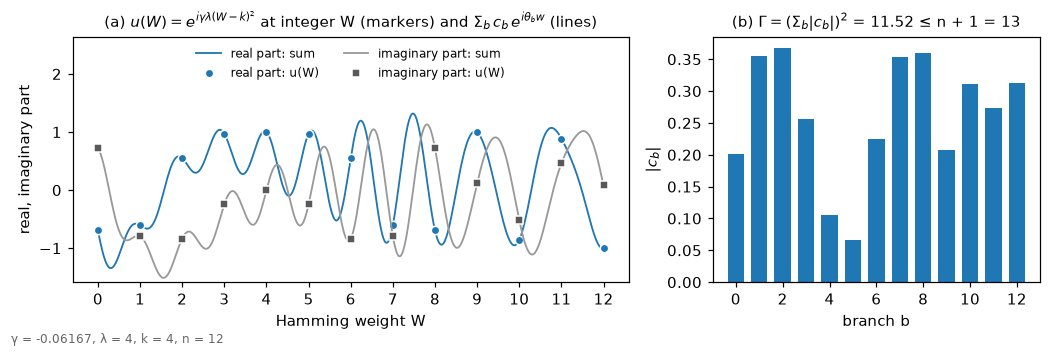

*(a) The Fourier sum is a smooth function of a continuous weight and passes exactly through the target $u(W)$ at every integer weight; integers are all a diagonal operator can see. (b) The magnitudes $|c_b|$, which set the weights $q_b$ and $\Gamma$.*

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 1b).</b>
<ul>
<li><b>Write:</b> the lines between <code>### your code</code> and <code>###</code> of <code>fourier_lcu(inst, gamma)</code>, in the next code cell. They assign <code>thetas</code>, <code>c</code>, <code>weights</code> and <code>Gamma</code>; the given <code>return thetas, c, weights, Gamma</code> fixes the order.</li>
<li><b>Input:</b> <code>inst</code>, the problem instance: use its <code>n</code>, <code>k</code> and <code>lam</code> (the given first line reads them), not fixed numbers. <code>gamma</code>, the cost angle γ, a float.</li>
<li><b>Return:</b> four values, in this order: <code>thetas</code>, the n+1 angles θ<sub>b</sub> = 2πb/(n+1), b = 0, …, n, in radians; <code>c</code>, the n+1 complex coefficients c<sub>b</sub>; <code>weights</code>, the n+1 probabilities q<sub>b</sub> = |c<sub>b</sub>|/‖c‖<sub>1</sub>; <code>Gamma</code>, one real number, Γ = ‖c‖<sub>1</sub><sup>2</sup>. Each of the three vectors may be a NumPy array or a list.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex1b(fourier_lcu, inst)</code>: the function itself, not its result, and the training instance. The grading function calls your function on your machine and sends what it returns.</li>
<li><b>The grader checks:</b> your function is called four times: on the training instance at γ = 0.37, 0.9 and 1.63, and on a second instance (n = 7, k = 3, λ = 5) at γ = 0.9, where a function with a fixed n, k or λ fails. For each call the grader checks that the three vectors have n+1 entries, the reconstruction Σ<sub>b</sub> c<sub>b</sub> e<sup>iθ<sub>b</sub>W</sup> = u(W) for W = 0, …, n with your angles and coefficients, to within 1e-5, the weights q<sub>b</sub> = |c<sub>b</sub>|/‖c‖<sub>1</sub> entry by entry, to within 1e-5, and Γ = ‖c‖<sub>1</sub><sup>2</sup> to a relative 1e-6, with Γ ≤ n+1. A known mistake, such as the complex conjugate of u(W) or a missing factor 1/(n+1), is named in the message.</li>
<li><b>Points:</b> 5, all or nothing. You can grade again; the best score counts.</li>
</ul></div>

<details><summary>Hint 1</summary>

Compute the $n+1$ values $u(W)$, $W = 0, \dots, n$, in one array, take their discrete Fourier transform, and divide by $n+1$.

</details>

<details><summary>Hint 2</summary>

With `W = np.arange(n + 1)` and `u` the array of the $u(W)$, the entry $b$ of `np.fft.fft(u)` is $\sum_{W=0}^{n} u(W)\, e^{-2\pi i\, bW/(n+1)} = (n+1)\,c_b$ for $b = 0, \dots, n$. So `c = np.fft.fft(u) / (n + 1)`, and the angles are `thetas = 2 * np.pi * np.arange(n + 1) / (n + 1)`.

</details>

<details><summary>Hint 3</summary>

The phase has a plus sign, `u = np.exp(1j * gamma * lam * (W - k) ** 2)`, because $H_2 = -\lambda(W-k)^2$ and the layer is $e^{-i\gamma H_2}$. If the grader's message mentions the complex conjugate, this sign is reversed. Then `weights = np.abs(c) / np.abs(c).sum()` and `Gamma = np.abs(c).sum() ** 2`.

</details>

In [ ]:
def fourier_lcu(inst, gamma):
    """Fourier LCU of the penalty phase u(W) = exp(+i gamma lam (W - k)^2).

    inst: the problem instance (uses inst.n, inst.k, inst.lam); gamma: the cost angle, a float.
    Returns, in this order: thetas (n+1 angles in radians), c (n+1 complex coefficients),
    weights (n+1 values |c_b| / sum_b |c_b|) and Gamma (one number, (sum_b |c_b|)**2).
    """
    n, k, lam = inst.n, inst.k, inst.lam
    ### your code
    raise NotImplementedError("Exercise 1b: compute thetas, c, weights and Gamma, then delete this line")
    ###
    return thetas, c, weights, Gamma

In [ ]:
grade_lab_tcfs_ex1b(fourier_lcu, inst)

In [ ]:
# angles that reproduce Table I, experiments 1-2 (recomputed by the kit; the paper does not list them)
gamma_star, beta_star = event.TABLE_I["ensemble"]
nb.lcu_report(inst, basis_circuit(inst), fourier_lcu, gamma_star, beta_star)

**Reading the report.** The table puts your rows next to the paper's Table I on this instance: the coherent circuit with the full penalty block (experiment 1), the LCU ensemble of your `fourier_lcu` at the same angles (experiment 2), and a single basis circuit with angles re-optimized by the kit in the setting of experiment 4. The table's CVaR is at level $1/\Gamma$, as in the paper; the challenge itself scores $\alpha = 0.10$ (Exercise 1d).
- The ensemble's mean of $f_\lambda$ is far below the coherent circuit's, because the ensemble mixes in branches that violate the constraint. Its CVaR at level $1/\Gamma$ is still above the coherent mean, as paper Sec. II B states: for samples $\tilde X$ of the ensemble and $X$ of the coherent circuit, the lower-tail and upper-tail CVaR of $f(\tilde X)$ at level $1/\Gamma$ enclose $\mathbb E[f(X)]$. The guarantee is about the best samples, not about the mean.
- The single trained circuit has the lowest mean and the highest probability of the optimum. Expectation values and sampling quality are different objectives, and this challenge scores sampling quality. In this reading `theta` is a Lagrange multiplier for the constraint (paper Sec. V). Part 2 uses this single-circuit form at 106 qubits; the ensemble is one of your options there.
- In the figure, every bitstring sits on or above the line $\tilde p = p/\Gamma$. $\Gamma$ depends on $\gamma$: it returns to 1 where $\gamma\lambda$ is a multiple of $2\pi$, because the penalty phase is then trivial, and at the $\gamma$ used here it is close to its bound $n+1$.

### Exercise 1c: Transpile for your backend (4 points)

Your circuit uses `ry`, `rz` and `rzz` gates, the `rzz` gates between arbitrary pairs of qubits. The backend offers `cz`, `rz`, `sx` and `x`, with `cz` only on a fixed set of qubit pairs. Transpilation rewrites the circuit in the backend's gates, chooses physical qubits and routes the two-qubit gates. The result is an **ISA circuit**, the only kind of circuit a primitive accepts.

Transpile the *parametrized* circuit once. The 13 branches differ only in the value bound to `theta`, so they all share this one ISA circuit.

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 1c).</b>
<ul>
<li><b>Write:</b> the lines between <code>### your code</code> and <code>###</code> in the next code cell; they must assign <code>isa</code>. The line <code>qc = basis_circuit(inst)</code> above them is given; the grading call is in the next cell, and the cell after it prints the cost table.</li>
<li><b>Start from:</b> <code>qc</code>, your parametrized basis circuit of Exercise 1a, already measured by its <code>measure_all()</code>: keep the measurements before transpiling; <code>backend</code>, your assigned backend of the setup cell; <code>generate_preset_pass_manager</code>, imported in the setup cell.</li>
<li><b>Produce:</b> <code>isa</code>, one <code>QuantumCircuit</code> that is ISA for your backend, still has the free parameters <code>gamma</code>, <code>theta</code> and <code>beta</code> (not bound: the PUB binds them later), keeps its 12 measurements in the one 12-bit register that <code>measure_all()</code> created, and has at most 60 two-qubit gates on <code>ibm_phoenix</code> (on this backend they are all <code>cz</code>; the bar is 89 on IBM's Heron processors, which need more routing).</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex1c(isa, backend)</code>: the circuit itself, not a list or a PUB, and your backend. The grading function sends the circuit, the backend's name and the circuit's number of two-qubit gates and two-qubit depth.</li>
<li><b>The grader checks:</b> that every operation is a gate of your backend and that every two-qubit gate acts on a pair of qubits that the backend couples (the grader holds the gates, couplings and bars of the IBM backends of the event; for another backend it checks the gates against the gate set of IBM's Heron processors, applies the bar 89 and skips the couplings, and its message says so); the three parameter names; the single 12-bit register; the number of two-qubit gates against the bar of your backend; and that the circuit is equivalent to the exact reference basis circuit at two fixed parameter sets, to within 1e-6, so it needs a correct Exercise 1a. For the equivalence it simulates the measured qubits and the qubits they interact with, at most 16; a level-3 transpilation keeps the circuit on 12 to 14 qubits. A known mistake, such as a circuit that was not transpiled, one transpiled at optimization level 0 or one without its measurements, is named in the message.</li>
<li><b>Points:</b> 4, all or nothing. Any valid circuit within the bar of your backend gets all 4 points; fewer gates earn nothing more. You can grade again; the best score counts.</li>
</ul>
Routing is heuristic: different values of <code>seed_transpiler</code> give different circuits, so try several and keep the best.</div>

<details><summary>Hint 1</summary>

`generate_preset_pass_manager(optimization_level=3, backend=backend, seed_transpiler=s).run(qc)` returns an ISA circuit for your backend; `s` is an integer seed.

</details>

<details><summary>Hint 2</summary>

Count the two-qubit gates with `isa.count_ops().get("cz", 0)`; the two-qubit depth is `isa.depth(lambda op: len(op.qubits) == 2)`.

</details>

<details><summary>Hint 3</summary>

Transpile with ten seeds, `for seed in range(10): ...`, collect the circuits in a list `candidates` and keep the one with the fewest `cz`: `isa = min(candidates, key=lambda c: c.count_ops().get("cz", 0))`.

</details>

In [ ]:
qc = basis_circuit(inst)
### your code
raise NotImplementedError("Exercise 1c: transpile qc for your backend and assign isa, then delete this line")
###

In [ ]:
grade_lab_tcfs_ex1c(isa, backend)

In [ ]:
nb.cost_comparison(inst, backend, isa)

This is the trade in numbers. One branch of the ensemble needs a fraction of the two-qubit gates of the circuit with the penalty block, and the gap grows with $n$: at 106 qubits the penalty block alone would need 5,565 two-qubit gates before routing. The last row, shown when `qopt-best-practices` is installed, routes the penalty circuit with a swap strategy made for gates on every pair of qubits.

### Exercise 1d: Run on the QPU and score the counts (6 points)

**Execute.** A `Sampler` job takes a list of PUBs (primitive unified blocs), each `(circuit, parameter values, shots)`. One PUB can carry many parameter sets for the same ISA circuit, so the whole ensemble is a single PUB with 13 rows of parameter values. A second PUB runs the single trained basis circuit for comparison; all PUBs of one job must have the same number of shots (here 4,096). The job cell submits with `jobs.run_once("practice", sampler, pubs)`: it calls `sampler.run(pubs)` the first time, keeps the job's id under the tag in the file `job_cache/jobs.json`, and afterwards returns the same job, so running the cell again, or the notebook after a restart, does not submit a second job. In plain Qiskit you would write `job = sampler.run(pubs)` and later fetch the job with `service.job(job_id)`. Use a new tag for every new job, because a known tag returns its earlier job; only a job that ended with ERROR, CANCELLED or FAILED is submitted again under the same tag, and `jobs.forget(tag)` drops a tag.

**Post-process.** A counts dictionary maps bitstrings to numbers of shots. Two conventions matter:
- Qiskit bitstrings are little-endian: qubit 0 is the *rightmost* character. `measure_all()` was placed before transpilation, so bit $i$ is still node $i$ whatever physical qubits were used.
- Shots of branch $b$ are pooled with weight $q_b$ divided by the number of shots of that branch.

**Why CVaR.** An optimization run is judged by its best samples, not by its average, which the penalized samples pull down. The **conditional value at risk** $\mathrm{CVaR}_\alpha$ is the average of $f_\lambda$ over the best fraction $\alpha$ of the probability mass: the average of a tail, not the single best sample, so a single good sample does not decide it. The challenge fixes $\alpha = 0.10$ for every team instead of $1/\Gamma$: teams choose very different $\Gamma$, and a team-dependent tail would give every team its own yardstick.

To compute it, sort the samples by value, best first, and average them with their weights until the accumulated weight reaches $\alpha$; the sample that crosses $\alpha$ counts only with the part that is still missing. With the values sorted as $v_1 \ge v_2 \ge \dots \ge v_M$ and their weights $w_1, \dots, w_M$ normalized to $\sum_{m=1}^{M} w_m = 1$:

$$\mathrm{CVaR}_\alpha = \frac{1}{\alpha}\sum_{m=1}^{M} v_m\,\min\Big(w_m,\ \max\big(\alpha - \textstyle\sum_{m'=1}^{m-1} w_{m'},\ 0\big)\Big).$$

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 1d).</b>
<ul>
<li><b>Write:</b> two regions of the next code cell, each between <code>### your code</code> and <code>###</code>. (1) In <code>evaluate_counts(inst, counts)</code>, the lines inside the loop that append f<sub>λ</sub>(x) to <code>values</code> and whether W(x) = k to <code>feasible</code> for the current <code>bitstring</code>; <code>shots.append(c)</code> and the <code>return</code> are given. (2) The whole body of <code>cvar(values, weights, alpha)</code>, including its <code>return</code>: no <code>return</code> is given outside the region. (3) Then run the job cell, the results cell and the grading cell after it; all three are given.</li>
<li><b>Input:</b> <code>evaluate_counts</code> takes <code>inst</code>, the problem instance, and <code>counts</code>, a dictionary that maps an n-character bitstring (qubit 0 is the rightmost character) to its number of shots, as <code>get_counts()</code> returns it. Use <code>inst.lam</code>, <code>inst.k</code> and the weight <code>w</code> of every edge, not fixed numbers: the grader also uses a 7-node instance with λ = 5 and an edge of weight 2, and Exercise 2a uses your function again on the 106-qubit instance. <code>cvar</code> takes <code>values</code> and <code>weights</code>, two sequences of equal length that arrive as Python lists (the reference cases) or as float NumPy arrays (the job data), so convert them with <code>np.asarray</code> before you index them with an array; the weights are positive and need not sum to 1. <code>alpha</code> is a float in (0, 1], 0.10 on the job.</li>
<li><b>Return:</b> <code>evaluate_counts</code> returns three sequences, <code>values</code> (the numbers f<sub>λ</sub>(x)), <code>feasible</code> (booleans) and <code>shots</code>, each a NumPy array or a list with one entry per key of <code>counts</code>, in the same order; not one triple per bitstring. <code>cvar</code> returns one number.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex1d(evaluate_counts, cvar, job, inst)</code>, in the grading cell after the results cell: your two functions, the job object that <code>jobs.run_once</code> returned (not its id, not <code>job.result()</code>), and the training instance. The last line of the code cell of this exercise only prints a self-check of <code>cvar</code> on the two values below; it sends nothing.</li>
<li><b>The grader checks:</b> the grading function calls your functions on your machine, <code>evaluate_counts</code> on synthetic counts of the training instance (60 bitstrings) and of a 7-node instance with λ = 5 and an edge of weight 2 (40 bitstrings), and <code>cvar</code> on 48 fixed cases, and reads the job: the counts of each of its 14 parameter sets. The grader compares the values to within 1e-9, <code>feasible</code> exactly and every CVaR to within 1e-9 with its reference. It requires a job of two PUBs, the 13 branches of the ensemble and then the single circuit, with at least 1,000 shots in every parameter set and 12-bit outcomes; it recomputes from the counts, with its own weights q<sub>b</sub>, the feasible fraction, the probability of the optimum and the CVaR of the ensemble and of the single circuit, and it checks that the single circuit's feasible fraction lies between 0.02 and 0.6, as for a 12-qubit run on hardware. A known mistake, such as the wrong bit order, f in place of f<sub>λ</sub> or the CVaR of the worst values, is named in the message.</li>
<li><b>Points:</b> 6, all or nothing. You can grade again, and running the job cell again does not submit a second job; the best score counts. The practice job uses about 5 s of your QPU time.</li>
</ul>
The weights of <code>cvar</code> need not sum to 1: they may be shot counts, or, as in the pooled ensemble below, q<sub>b</sub> times the count divided by the shots of branch b; normalize them first. Two values to test <code>cvar</code> with: <code>cvar([1, 2], [1, 3], 0.5)</code> is 2.0, and <code>cvar([1, 2], [1, 3], 0.8)</code> is (0.75·2 + 0.05·1)/0.8 = 1.9375.</div>

<details><summary>Hint 1</summary>

`evaluate_counts`: for each bitstring, recover the bit of every node, then compute $f$, the Hamming weight $W$, the value $f_\lambda$ and whether $W = k$. `cvar`: sort the samples from the best value to the worst, normalize the weights, walk down the sorted list until the accumulated weight reaches $\alpha$, and average the values over that tail, the last sample only with the part of its weight that is still missing.

</details>

<details><summary>Hint 2</summary>

For a bitstring `s` of length $n$: $x_i$ is `int(s[n - 1 - i])` for $i = 0, \dots, n-1$ (Qiskit bitstrings are little-endian); $f(x) = \sum_{(i,j,w)} w\, x_i x_j$ over the tuples of `inst.edges`; $W(x) = \sum_{i=0}^{n-1} x_i$; the value is $f_\lambda(x) = f(x) - \lambda\,(W(x) - k)^2$ with $\lambda$ = `inst.lam` and $k$ = `inst.k`; feasible means $W(x) = k$. For the CVaR, with the values sorted as $v_1 \ge \dots \ge v_M$ and the weights normalized to sum 1, sample $m$ contributes $t_m = \min\big(w_m,\ \max(\alpha - \sum_{m'=1}^{m-1} w_{m'},\ 0)\big)$, and $\mathrm{CVaR}_\alpha = \frac{1}{\alpha}\sum_{m=1}^{M} v_m\, t_m$.

</details>

<details><summary>Hint 3</summary>

Near-code for both regions:

```python
# evaluate_counts, inside the loop
x = np.array([int(ch) for ch in bitstring[::-1]])     # x[i] = node i
f = sum(w * x[i] * x[j] for i, j, w in inst.edges)
values.append(f - inst.lam * (x.sum() - inst.k) ** 2)
feasible.append(x.sum() == inst.k)

# cvar
order = np.argsort(values)[::-1]
v, w = np.asarray(values, float)[order], np.asarray(weights, float)[order]
w = w / w.sum()
before = np.concatenate([[0.0], np.cumsum(w)[:-1]])   # weight ahead of each sample
take = np.clip(alpha - before, 0.0, w)
return float((v * take).sum() / alpha)
```

</details>

In [ ]:
def evaluate_counts(inst, counts):
    """Arrays (values, feasible, shots) for a Qiskit counts dictionary.

    inst: the problem instance; counts: {bitstring: shots}, qubit 0 is the rightmost character.
    Returns: values (f_lambda), feasible (W == k) and shots, one entry per key of counts.
    """
    values, feasible, shots = [], [], []
    for bitstring, c in counts.items():
        ### your code
        raise NotImplementedError("Exercise 1d: append f_lambda(x) to values and W(x) == k to feasible, then delete this line")
        ###
        shots.append(c)
    return np.array(values, float), np.array(feasible), np.array(shots, float)

def cvar(values, weights, alpha):
    """Weighted mean of the best alpha-fraction of the probability mass.

    values, weights: lists or arrays of equal length (weights > 0, any sum); alpha in (0, 1].
    Returns: one number, the CVaR_alpha of the values.
    """
    ### your code
    raise NotImplementedError("Exercise 1d: return the CVaR of values with weights at level alpha, then delete this line")
    ###

print(f"self-check: cvar([1, 2], [1, 3], 0.5) = {cvar([1, 2], [1, 3], 0.5):.4f} (expected 2.0000), "
      f"cvar([1, 2], [1, 3], 0.8) = {cvar([1, 2], [1, 3], 0.8):.4f} (expected 1.9375)")

In [ ]:
thetas, c, weights, Gamma = fourier_lcu(inst, gamma_star)
single = event.TABLE_I["single"]                 # angles re-optimized by the kit in the setting of Table I, experiment 4
shots = 4096
pubs = [
    (isa, {"gamma": [gamma_star] * len(thetas), "beta": [beta_star] * len(thetas), "theta": thetas}, shots),
    (isa, {"gamma": single["gamma"], "beta": single["beta"], "theta": single["theta"]}, shots),
]
sampler = Sampler(mode=backend)                  # job mode
job = jobs.run_once("practice", sampler, pubs)

In [ ]:
result = job.result()                                             # waits for the job
ensemble_counts = [result[0].data.meas.get_counts(b) for b in range(len(thetas))]
single_counts = result[1].data.meas.get_counts()
nb.part1_results(inst, ensemble_counts, weights, single_counts, evaluate_counts, cvar)

In [ ]:
grade_lab_tcfs_ex1d(evaluate_counts, cvar, job, inst)

In the histogram the highlighted bars are the best 10 % of the probability mass, the tail that $\mathrm{CVaR}_{0.10}$ averages; the solid and dashed lines mark the CVaR and the mean.

**Part 1 summary.** You have the four pieces of the method as Qiskit code: a parametrized basis circuit, the LCU branches and weights, an ISA circuit, and the scoring of counts. In the ideal rows of the table, the single trained circuit has the higher CVaR and samples the optimum more often than the ensemble, as in the paper's Table I; this is why Part 2 starts from a single circuit. Part 2 uses the kit's versions of the same pieces at 106 qubits.

## Part 2: The campaign (65 points)

You now run the method on your own 106-qubit instance, on your backend. Statevector simulation is not feasible at this size (paper Sec. VI C), so the output distribution comes only from the QPU. Part 2 takes you through a first job and a first improvement step by step, and then leaves the campaign to you.

**Your tasks in Part 2, in order**

| task | what you do | do you write code? | what it gives |
|---|---|---|---|
| Steps 1 to 4 | choose the angles `(gamma, theta, beta)` classically (Step 1), build the circuit for your instance and transpile it (Step 2), run it as a `Sampler` job and look at the counts (Step 3), grade the job with `grade_lab_tcfs_ex2e` (Step 4) | no: run the cells as given | your first graded job and its score $S$ |
| Exercise 2a | score the counts yourself: $\mathrm{CVaR}_{0.10}$ and $F$ from all shots of one counts dictionary | yes: the function `my_score` | 2 points, and the scoring function for all your later jobs |
| Exercise 2b | correct the LCU angle with what you measured, run the re-centred job and grade it | yes: `shift`, `theta_c`, the circuit, the job and its counts | 3 points, and your second graded job |
| Exercise 2c | a sweep: eight values of `theta` in one job, every setting scored with `my_score` | yes: the sweep PUB, the job and the scores | 3 points, and the best `theta` for your next job |
| Exercise 2d | plan the QPU time of the rest of the campaign; `nb.plan` estimates it | yes: the rows of `my_plan` | 2 points |
| Exercise 2e, the open campaign (Step 5) | your own jobs: sweeps, error suppression, an ensemble, another circuit, each graded with `grade_lab_tcfs_ex2e` | yes: one new cell per job, copied from the template cell after Exercise 2c (a sweep from the cell of Exercise 2c, an ensemble from the code of "An ensemble job" in Part 3) | 55 $\times \min(S/0.20,\ 1)$ points from your best job |

While a job waits in the queue, work on what needs no QPU time: Exercise 2a and the first cell of Exercise 2b while the baseline job runs, and Exercise 2d at any time. The open campaign starts with Exercise 2c; its rules, levers and tools are in Step 5, the section between Exercises 2b and 2c.

**When Part 2 is complete.** Your 10 exercise points are final once Exercises 2a to 2d have passed. Exercise 2e stays open until the event closes: every job you grade with `grade_lab_tcfs_ex2e` is scored, and your best score counts, so a better job raises your points and a worse one costs only its QPU time. `check_progress()` shows your scores at any time. There is nothing to upload: the grading server keeps your best score for every exercise.

**What is fixed and what is yours**
- Fixed: the instance, the cost function $f_\lambda$, the score formula, at least 1,000 shots per graded job, job mode or Batch.
- Yours: the angles, the number of shots, one circuit or an ensemble, the error-suppression options of the sampler, the transpilation, and the depth and the circuit family (Part 3).

There is no limit on the number of jobs you grade and no waiting time between gradings: what limits your jobs is your QPU time. A one-layer job of $2^{15}$ shots uses about 3.4 s, and one job can carry many parameter settings in one PUB (Exercise 2c).

<div class="alert alert-block alert-success">✏️ <b>Part 2.</b> Solve Exercises 2a to 2d (10 points; each is graded by the call in its grading cell) and reach the highest job score S you can on your 106-qubit instance (Exercise 2e, 55 points; your best graded job counts).</div>

### The score of a job

**Read.** This is how the grader scores every job you grade with Exercise 2e; there is nothing to run in this section.

$$S = 0.7\,Q + 0.2\,F$$

| | |
|---|---|
| $Q$ | quality: $\big(\mathrm{CVaR}_{0.10}(f_\lambda) - B\big)/(\mathrm{OPT} - B)$, clipped to $[0, 1]$. OPT is the optimum of your instance. $B$ is the $\mathrm{CVaR}_{0.10}$ of the initial state alone, so a circuit that does not improve on its initial state has $Q = 0$ |
| $F$ | the fraction of your samples that are feasible ($W = k$) |

Exercise 2e gives $55 \times \min(S/0.20,\ 1)$ points for your best graded job: $S = 0.20$ earns all 55 points, $S = 0.10$ half of them, and a job with $Q = 0$ earns nothing. 0.20 is about the published state of the art on hardware ("What is a good score", below). With the 10 points of Exercises 2a to 2d this makes the 65 points of Part 2. OPT and $B$ of your instance are not given to you: the grading server holds them, and its message describes your CVaR relative to them without revealing them.

**How precise a score is.** The grader computes $Q$ and $F$ from a sample of 4,096 of your shots, which the grading function draws without replacement and with a fixed seed: the same job always gives the same sample and the same $S$. Against the $S$ of all shots of a $2^{15}$-shot job, the sample's $S$ differs by about 0.006 (one standard deviation, measured on twelve of the organizers' jobs below). Repeats of the same 32,768-shot job differed by about 0.003 in $S$ computed from all shots. So two graded scores that differ by less than about 0.02 are not clearly different. To compare your own jobs and settings, use the full-count $\mathrm{CVaR}_{0.10}$ and feasible fraction that you compute yourself in Exercise 2a: $Q$ rises with $\mathrm{CVaR}_{0.10}$. These numbers have a statistical error too (subsamples of the organizers' jobs below): with 4,096 shots, the $\mathrm{CVaR}_{0.10}$ of one counts dictionary has a standard deviation of about 0.65 and $F$ of about 0.003; with $2^{15}$ shots, about 0.23 and 0.001.

### What is a good score

**Read, then run the cell at the end of this section as given.** The published and measured scores below give you a scale for your own; the cell prints your 106-qubit instance.

The authors ran each of their two trained circuit types ten times on their own 106-qubit instance on IBM hardware. Scored with the formula above, the trained penalty-basis circuit (paper experiment 4) reaches a median $Q$ of 0.16 and a best $Q$ of 0.22, the trained XY-basis circuit (experiment 5) a median of 0.21 and a best of 0.25, with $F$ between 0.04 and 0.08. $Q$ is near 0.2 and not near 1 because it is measured against the true optimum: with a feasible fraction of about 5 %, the best 10 % of the samples of a 106-qubit run necessarily include many infeasible strings, which pay the penalty. That is also why $F$ is scored separately. A $Q$ near 0.2 is the state of the art on hardware, and the published results are the line to beat: the best of them, $Q$ about 0.25 with $F$ about 0.08, gives $S$ about 0.19.

**What the organizers measured** on the demo instance on `ibm_phoenix` on 2026-09-30, with one-layer circuits. The first four rows are calibration runs at $\gamma = -0.75$, scored from all shots of each job; the last rows are this notebook's own run, scored from a sample of 4,096 shots:

| circuit | result |
|---|---|
| baseline type: $\beta = 0.50$, `theta` for an ideal mean weight of 35; six repeats of 32,768 shots | $S$ = 0.141 (sd 0.002), $Q$ = 0.19, $F$ = 0.041; measured mean weight 39.6, 4.6 above the ideal 35 |
| the same with `theta` re-solved for an ideal mean weight of 30.5; six repeats | $S$ = 0.164 (sd 0.003), $Q$ = 0.22, $F$ = 0.049; measured mean weight 35.5 |
| $\beta$ scan at an ideal mean weight of 31.5, 8,192 shots per setting | $S$ = 0.139, 0.161, 0.170, 0.149, 0.122 at $\beta$ = 0.32, 0.40, 0.50, 0.60, 0.75 |
| $\gamma$ scan at $\beta = 0.40$, in the same job | $S$ = 0.147, 0.161, 0.137 at $\gamma$ = −0.55, −0.75, −0.95 |
| the baseline and the re-centred job of this notebook, with the kit's angles ($\gamma = -0.726$, $\beta = 0.504$), one job each in the evening of the same day | $S$ = 0.154 and 0.185; measured mean weight 39.0 and 35.9; $\mathrm{CVaR}_{0.10}$ from all shots 60.5 and 63.0 |
| the theta sweep of this notebook (Exercise 2c): eight values of `theta` from 4.058 to 4.458 around the re-centred 4.258, 4,096 shots each, in one job | measured mean weight from 32.7 to 39.1, about 0.9 per step; $\mathrm{CVaR}_{0.10}$ from all shots between 61.2 and 63.1 for the seven lower values, 60.0 at the highest, with a statistical error of about 0.65 per value; scored as one pooled job, $S$ = 0.170 |
| two layers, each with the re-centred job's `gamma` and `theta_c` and half its `beta` (the example of Exercise 3d in Part 3), one job | $S$ = 0.088 against 0.185 for the one-layer control; measured mean weight 40.0 |

On the scale of Exercise 2e, the re-centred job's $S$ = 0.185 is worth $55 \times 0.185/0.20 = 50.9$ points. The organizers did not test dynamical decoupling, gate twirling, the ensemble at 106 qubits or the XY basis circuit. These numbers hold for the demo instance and one calibration day: they give a scale, not targets.

**Your instance.** It has 106 nodes and is laid out on your backend so that its circuit needs no routing; the setup cell loaded it from your handout file, or loaded the demo instance.

In [ ]:
print(f"instance {inst106.instance_id}: n = {inst106.n}, edges = {len(inst106.edges)}, "
      f"k = {inst106.k}, lambda = {inst106.lam:.0f}")

### Step 1: Choose the angles without a simulator

**Run as given.** Nothing to write: run the cell and look at the printed layer `(gamma, theta, beta)` and its ideal mean weight, which Exercise 2b starts from.

The three angles of one layer have separate roles:
- `gamma` sets how strongly the cost layer writes the objective into the phases of the bitstrings;
- `beta` sets how far the mixer turns those phases into changes of the bitstring probabilities ($\beta = 0$ returns the distribution of the initial state);
- `theta` shifts the mean Hamming weight.

For a circuit with one layer, the mean and variance of the Hamming weight $W$ and the mean of $f$ can be computed exactly on a laptop: the mixer and the LCU layer are single-qubit gates, so after one layer two qubits are correlated only if they are neighbours or share a neighbour. `hw.layer_expectations(inst, gamma, theta, beta)` does this in milliseconds; it takes the angles in the order of the layer tuples `(gamma, theta, beta)`.

The paper reads `theta` as the Lagrange multiplier of the constraint (Sec. V). The kit uses this reading: for each candidate pair (`gamma`, `beta`) it solves `theta` so that the expected Hamming weight equals $k$, and it keeps the pair with the largest expected $f$. This rule is the kit's own; the paper chose its 106-qubit angles from the analytic expectation value and then optimized them on the hardware (Sec. VI C).

**Reading the output.** The printed line gives the chosen layer and its ideal moments. The heat map shows the ideal $\langle f\rangle$ on the grid of (`beta`, `gamma`), with `theta` solved for $\langle W\rangle = k$ at each point, and marks the chosen pair. The panels on the right show, at the chosen pair, how `theta` moves $\langle W\rangle$ along a sinusoid and $\langle f\rangle$ with it; the rule picks the crossing with $k$ that has the larger $\langle f\rangle$. These are ideal one-layer means: they contain no noise, and the score is a tail (CVaR), not a mean. They tell you where to start.

In [ ]:
layers, info = hw.lagrangian_layers(inst106)     # [(gamma, theta, beta)] and the ideal moments
nb.expectations(info, inst106)

### Step 2: Build and transpile

**Run as given.** Nothing to write: run the cell and look at the number of `cz` gates and the QPU seconds of one job in the cost table.

`hw.hardware_basis_circuit_p` builds the four layers of your `basis_circuit` for your instance. Its cost layer contains two SWAP layers, which is why it has more two-qubit gates than the graph has edges (the construction of paper Appendix F, which uses three). The pass manager then only translates to the backend's gates and merges neighbouring gates. The cost table gives the number of `cz` gates, the two-qubit depth, the duration of one shot and the QPU seconds of a job with this one circuit and $2^{15}$ shots.

In [ ]:
qc106, _ = hw.hardware_basis_circuit_p(inst106, layout, layers, swap_last=True)
pm106 = hw.resynth_pass_manager(backend.target, layout.physical)
isa106 = pm106.run(qc106)
nb.circuit_cost(isa106, backend)

### Step 3: Run the job and look at the counts

**Run as given.** Nothing to write: the first cell submits your baseline job and the second waits for its counts; look at the printed `mean W` against $k$ and at the feasible fraction.

The job cell creates a `Sampler` in job mode, switches measurement twirling on (all other options stay at their defaults) and submits one PUB, the ISA circuit with $2^{15}$ shots, through `jobs.run_once` with the tag `"baseline"`, as in Exercise 1d. The next cell waits for the result and draws the histogram of the Hamming weight. Its printed line gives the mean of $W$ against $k$, the spread sd($W$), the feasible fraction, the mean $f$ of the feasible samples and the best feasible $f$. A better circuit has its mean $W$ closer to $k$, a smaller spread, a larger feasible fraction and larger values of $f$ among the feasible samples.

In [ ]:
sampler = Sampler(mode=backend)                            # job mode
sampler.options.twirling.enable_measure = True              # measurement twirling
job = jobs.run_once("baseline", sampler, [(isa106,)], shots=2**15)

In [ ]:
counts = job.result()[0].data.c.get_counts()                # waits for the job; the register is named c
stats = nb.weight_histogram(inst106, counts, ideal=info)

### Step 4: Grade the job

**Run as given.** Nothing to write: the printed answer is your first graded score $S$, with your points for Exercise 2e.

Grade the job with `grade_lab_tcfs_ex2e(job, inst106, lcu=None, note="baseline")`. The grading function reads the finished job on your machine, draws a sample of 4,096 of its shots with a fixed seed, and sends the sample with the job id, the backend, the QPU usage, the number of shots and your instance id; the grader computes $Q$, $F$ and $S$ from the sample with the OPT and $B$ of your instance and prints them, with the CVaR and your points. Grade every job you want counted, whatever its result: there is no registration and no waiting time between gradings, and your best score counts, so a worse job never lowers it. You may look at the counts first. Exercise 2a and the first cell of Exercise 2b need no QPU time and fit into the time the next job waits in the queue.

`lcu=None` declares a single circuit; a job with several PUBs or parameter sets and `lcu=None` is scored as one distribution that pools all their shots. An ensemble is declared by its construction, `lcu={"kind": "penalty", "gamma": gamma}`: the parameter sets of its PUB must be the branches $b = 0,\dots,n$ in this order, a subset is declared with `"branches": [b, ...]`, and the grading function computes the weights $q_b$ itself and draws each sampled shot from branch $b$ with probability $q_b$. `layers` (default 1) is the number of layers of your circuit, and `note` a short label for your own reference.

In [ ]:
grade_lab_tcfs_ex2e(job, inst106, lcu=None, note="baseline")

### Exercise 2a: Score your own counts (2 points)

**Your turn.** Write `my_score` in the next cell; the task box below says what it takes and returns and how the grader tests it.

The graded $S$ comes from a sample of 4,096 shots, and a sweep job is scored as one pooled distribution, so the grader never tells you which setting of a sweep was best. Your own scoring function does: it computes $\mathrm{CVaR}_{0.10}$ and $F$ from all shots of one counts dictionary, with the functions you wrote in Exercise 1d. With the `evaluate_counts` of Exercise 1d, a job of $2^{15}$ shots at 106 qubits, where almost every bitstring is distinct, takes about 20 seconds to score on a laptop.

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 2a).</b>
<ul>
<li><b>Write:</b> the three regions of <code>my_score(counts, alpha=0.10)</code> in the next code cell, under <code>### 1.</code> to <code>### 3.</code>: <code>values, feasible, shots</code>, then <code>tail</code>, then <code>F</code>, computed from all shots with your <code>evaluate_counts</code> and <code>cvar</code> of Exercise 1d. The header and <code>return tail, F</code> are given. Keep the parameter name <code>alpha</code> and its default 0.10: the grading function calls <code>my_score(counts)</code> and <code>my_score(counts, alpha=0.25)</code>.</li>
<li><b>Input:</b> <code>counts</code>, a dictionary that maps a 106-character bitstring of your 106-qubit instance to its number of shots, as <code>get_counts()</code> returns it; <code>alpha</code>, the CVaR level, a float. The function uses <code>inst106</code> and your <code>evaluate_counts</code> and <code>cvar</code>.</li>
<li><b>Return:</b> the pair <code>(tail, F)</code>, in this order: <code>tail</code>, the CVaR<sub>α</sub> of f<sub>λ</sub> over all shots, and <code>F</code>, the fraction of the shots whose bitstring is feasible, a number in [0, 1]. A tuple, a list or a NumPy array of two numbers passes, as Python floats or NumPy <code>float64</code>; <code>float32</code> is not precise enough.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex2a(my_score, inst106)</code>: the function itself, not its result, and your instance. The grading function calls your function on your machine and sends the pairs it returns, with the id of your instance.</li>
<li><b>The grader checks:</b> the grading function builds three probe counts dictionaries for your instance (1,500 distinct bitstrings each, from a fixed seed) and calls your function on each at the default α, and once more on the first with α = 0.25. The grader builds the same dictionaries and compares every pair with its own CVaR and F, computed from the edges and λ of your instance: the CVaR to within 1e-6 and F to within 1e-9. It does not use your job's counts; the four calls take a few seconds. A known mistake, such as the two numbers swapped, α ignored, the plain mean in place of the CVaR, or F counted over distinct bitstrings, is named in the message.</li>
<li><b>Points:</b> 2, all or nothing. You can grade again; the best score counts.</li>
</ul>
The cell prints your two numbers for the baseline job next to the kit's <code>hw.metrics_from_counts</code>; the next cell grades.</div>

<details><summary>Hint 1</summary>

Reuse your functions of Exercise 1d: `evaluate_counts` turns the counts into values, feasible flags and shots, one entry per bitstring; `cvar` of the values, with the shots as weights, is the CVaR; $F$ is the share of the shots that fall on feasible bitstrings.

</details>

<details><summary>Hint 2</summary>

`evaluate_counts(inst106, counts)` returns `(values, feasible, shots)`. `cvar(values, shots, alpha)` takes the shot counts as weights and normalizes them itself. With $n_x$ the shots of bitstring $x$, $F = \sum_{x\ \text{feasible}} n_x \,/\, \sum_x n_x$; in numpy, index `shots` with the feasible flags as a boolean array.

</details>

<details><summary>Hint 3</summary>

Near-code for the three regions:

```python
values, feasible, shots = evaluate_counts(inst106, counts)
tail = cvar(values, shots, alpha)
F = shots[np.asarray(feasible, dtype=bool)].sum() / shots.sum()
```

</details>

In [ ]:
def my_score(counts, alpha=0.10):
    """(CVaR_alpha of f_lambda, feasible fraction) of one counts dictionary of the 106-qubit instance.

    counts: {bitstring: shots}; alpha: the CVaR level, a float (keep this name and its default).
    Returns: (tail, F), two floats: the CVaR_alpha of f_lambda over all shots, then the feasible fraction.
    """
    ### 1. values, feasible flags and shots of every bitstring: your evaluate_counts, with inst106
    ### 2. tail: the CVaR_alpha of the values, weighted by the shots (your cvar)
    ### 3. F: the shots of the feasible bitstrings divided by all shots
    raise NotImplementedError("Exercise 2a: compute values, feasible, shots, tail and F under the numbered comments, then delete this line")
    ###
    return tail, F

mine, kit = my_score(counts), hw.metrics_from_counts(inst106, counts)
print(f"yours: CVaR_0.10 = {mine[0]:.2f}, F = {mine[1]:.4f}    kit: CVaR_0.10 = {kit['CVaR']:.2f}, F = {kit['F']:.4f}")

In [ ]:
grade_lab_tcfs_ex2a(my_score, inst106)

### Exercise 2b: Re-centre theta with what you measured (3 points)

**Your turn.** Compute the corrected angle in the first cell below, then build, run and read the re-centred job in the second; the task box lists every name to produce.

The angles were chosen for an ideal mean Hamming weight of exactly $k$, but noise moves the distribution: compare the printed `mean W` of Step 3 with $k$. Gate errors act roughly like depolarizing noise, which moves every qubit toward the maximally mixed state, whose mean Hamming weight is $n/2 = 53$; $k = 35$ is below that, so expect the measured mean weight above the ideal one. `theta` is the knob for the mean weight, so correct it with your own data: solve `theta` again for the ideal target $k$ minus the measured shift (measured mean minus ideal mean). `gamma` and `beta` stay as they are.

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 2b).</b>
<ul>
<li><b>Write:</b> two cells. In the first, under <code>### 1.</code> and <code>### 2.</code>: <code>shift</code> and <code>theta_c</code>. In the second, under <code>### 1.</code> to <code>### 3.</code>: <code>qc_c</code> and <code>isa_c</code>, then <code>job_c</code>, then <code>counts_c</code>. The line <code>gamma, theta, beta = layers[0]</code>, the printed lines, the histogram and <code>my_score</code> are given, and the two grading calls follow in a cell of their own.</li>
<li><b>Start from:</b> <code>stats</code>, the dictionary that <code>nb.weight_histogram</code> returned in Step 3, where <code>stats["mean_W"]</code> is the measured mean Hamming weight of the baseline job; <code>info</code>, the ideal moments of Step 1, where <code>info["exp_W"]</code> is the ideal mean weight; <code>layers</code>, the list of Step 1 with the one layer <code>(gamma, theta, beta)</code>, whose floats the given first line unpacks; <code>inst106</code> and <code>layout</code>, loaded by the setup cell; <code>pm106</code> of Step 2; <code>sampler</code> of Step 3.</li>
<li><b>Produce:</b> <code>shift</code>, a float, the measured minus the ideal mean weight (positive on hardware); <code>theta_c</code>, one real number in radians, the angle whose ideal mean weight is k − shift at the <code>gamma</code> and <code>beta</code> of Step 1 (<code>hw.theta_for_weight</code> returns a float in [0, 2π)); <code>qc_c</code>, the circuit of Step 2 with <code>(gamma, theta_c, beta)</code> as its layer tuple, with no free parameter and its register <code>c</code>; <code>isa_c</code>, its ISA circuit from <code>pm106</code>; <code>job_c</code>, the job object that <code>jobs.run_once</code> returns for the tag <code>"recentred"</code>, the PUB <code>(isa_c,)</code> and <code>shots=2**15</code>; <code>counts_c</code>, the counts dictionary of the job.</li>
<li><b>Hand to the grader:</b> in the grading cell after the second cell, <code>grade_lab_tcfs_ex2b(job_c, theta_c, stats, layers, inst106)</code>: the job object (not its id), your <code>theta_c</code>, the baseline's <code>stats</code> (not <code>stats_c</code>), the <code>layers</code> of Step 1 and your instance. The grading function sends the angle, the baseline's measured mean weight, the Step 1 layer and a sample of 4,096 shots of the job. The same cell also grades <code>job_c</code> for Exercise 2e, because the re-centred job is your best job so far. The first cell grades nothing: it prints a self-check of <code>theta_c</code>.</li>
<li><b>The grader checks:</b> it recomputes the ideal mean weight of the Step 1 layer and of (γ, θ<sub>c</sub>, β) with the one-layer formula of <code>hw.layer_expectations</code>, takes the shift as <code>stats["mean_W"]</code> minus the ideal mean weight of Step 1, and requires the ideal mean weight at <code>theta_c</code> to lie within 0.05 of k − shift (either angle that reaches the target passes; angles are compared modulo 2π). From the sample of the job it requires at least 1,000 shots in the job and a mean Hamming weight strictly closer to k than <code>stats["mean_W"]</code>. A known mistake, such as <code>theta</code> left unchanged, the shift with the wrong sign or the shift not applied, is named in the message.</li>
<li><b>Points:</b> 3, all or nothing. You can grade again, because <code>run_once</code> does not submit the job a second time; the best score counts.</li>
</ul>
The printed lines of the first cell show <code>shift</code> and <code>theta_c</code> before any QPU time is spent: expect a positive shift, and an ideal mean weight at <code>theta_c</code> that equals the target, which lies below k, so the self-check gap is close to 0. The second cell then draws the histogram and scores the counts with your <code>my_score</code>, and the grading cell grades the job twice. They are the model for every further job.</div>

<details><summary>Hint 1</summary>

The shift is the measured mean weight minus the ideal one: `stats` holds the measured numbers of Step 3 and `info` the ideal moments of Step 1. Ask the kit for the angle whose ideal mean weight is $k$ minus that shift, with `gamma` and `beta` unchanged. The job cell repeats Steps 2 and 3 with the new angle and a new tag.

</details>

<details><summary>Hint 2</summary>

`shift = stats["mean_W"] - info["exp_W"]`, and `hw.theta_for_weight(inst106, gamma, beta, target=inst106.k - shift)` returns `theta_c`. For the job: `hw.hardware_basis_circuit_p(inst106, layout, [(gamma, theta_c, beta)], swap_last=True)` returns `(circuit, sigma)`; `pm106.run(circuit)` is the ISA circuit; `jobs.run_once("recentred", sampler, [(isa_c,)], shots=2**15)` is the job; `job_c.result()[0].data.c.get_counts()` are its counts. If the printed shift is negative, the subtraction is reversed.

</details>

<details><summary>Hint 3</summary>

Near-code for the two cells:

```python
# first cell
shift = stats["mean_W"] - info["exp_W"]
theta_c = hw.theta_for_weight(inst106, gamma, beta, target=inst106.k - shift)

# second cell
qc_c, _ = hw.hardware_basis_circuit_p(inst106, layout, [(gamma, theta_c, beta)], swap_last=True)
isa_c = pm106.run(qc_c)
job_c = jobs.run_once("recentred", sampler, [(isa_c,)], shots=2**15)
counts_c = job_c.result()[0].data.c.get_counts()
```

</details>

In [ ]:
gamma, theta, beta = layers[0]
### 1. shift: the measured mean Hamming weight (stats["mean_W"]) minus the ideal one (info["exp_W"])
### 2. theta_c: the angle whose ideal mean weight is inst106.k - shift (hw.theta_for_weight)
raise NotImplementedError("Exercise 2b: compute shift and theta_c under the numbered comments, then delete this line")
###
ideal_c = hw.layer_expectations(inst106, gamma, theta_c, beta)
print(f"shift = {shift:+.2f}, theta {theta:.4f} -> {theta_c:.4f}, ideal mean weight at theta_c = "
      f"{ideal_c['exp_W']:.2f} (target {inst106.k - shift:.2f})")
print(f"self-check: ideal mean weight minus target = {ideal_c['exp_W'] - (inst106.k - shift):+.3f} "
      "(the grader accepts at most 0.05 either way)")

In [ ]:
### 1. qc_c and isa_c: the circuit with theta_c in the layer tuple and its ISA circuit (as in Step 2)
### 2. job_c: the job, with the same sampler, 2**15 shots and the new tag "recentred" (as in Step 3)
### 3. counts_c: the counts of the job
raise NotImplementedError("Exercise 2b: build qc_c and isa_c, run job_c and read counts_c under the numbered comments, then delete this line")
###
stats_c = nb.weight_histogram(inst106, counts_c)
print("yours: CVaR_0.10 = {:.2f}, F = {:.4f}".format(*my_score(counts_c)))

In [ ]:
grade_lab_tcfs_ex2e(job_c, inst106, lcu=None, note="theta re-centred")
grade_lab_tcfs_ex2b(job_c, theta_c, stats, layers, inst106)

### Step 5: Your own jobs, the open campaign (Exercise 2e, 55 points)

**Your turn.** This is the open campaign: from here on you choose, run and grade your own jobs on your 106-qubit instance, until the event closes. Every job you want counted goes through `grade_lab_tcfs_ex2e`; only your best score counts, for $55 \times \min(S/0.20,\ 1)$ points, and a worse job costs only its QPU time. Exercises 2c and 2d below are part of the campaign, and the template cell after Exercise 2c is the model for every job.

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 2e).</b>
<ul>
<li><b>Write:</b> one new cell per job, copied from the template cell after Exercise 2c: the parameters, the circuit and its ISA circuit, the job, a look at its counts and the grading call.</li>
<li><b>Start from:</b> your best job so far and the levers of the table "What you can change" below; <code>inst106</code>, <code>layout</code>, <code>pm106</code>, <code>sampler</code> and your <code>my_score</code>.</li>
<li><b>Produce:</b> a finished <code>Sampler</code> job on your 106-qubit instance, run on your assigned backend, with at least 1,000 shots: one circuit, a PUB with several parameter sets, or an LCU ensemble (Part 3).</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex2e(job, inst106, lcu=None, layers=1, note="")</code>: the job object (not its id), your instance, the declaration <code>lcu</code> (<code>None</code>, or <code>{"kind": "penalty", "gamma": gamma}</code> for an ensemble), the number of layers of the circuit (or its list of layer tuples) and a short note. The grading function sends a sample of 4,096 shots of the job, as in Step 4.</li>
<li><b>The grader checks:</b> that the job ran on an IBM backend, not on a simulator, with at least 1,000 shots, and that the sampled bitstrings are as wide as your instance; it computes the CVaR<sub>0.10</sub>, Q, F and S of the sample with the OPT and B of your instance. The job passes when Q > 0.</li>
<li><b>Points:</b> 55 × min(S/0.20, 1), rounded to two decimals, when Q > 0, and 0 when Q = 0. Grade every job you want counted; your best score counts.</li>
</ul></div>

**The working loop**, once per job:
1. choose one lever from the table "What you can change" below;
2. predict its effect with the classical functions where one exists: `hw.layer_expectations`, `hw.theta_for_weight` and `hw.lagrangian_layers` for the angles;
3. build and transpile the circuit, and look at its cost with `nb.circuit_cost`;
4. run it with a new tag in `jobs.run_once`;
5. score its counts with `my_score`;
6. grade it with `grade_lab_tcfs_ex2e(my_job, inst106, note="...")`;
7. keep the better setting, and start again at 1.

Steps 1 to 3 need no QPU time: prepare the next job while the last one waits in the queue.

**How to judge a job.** Three numbers explain most of a score: the mean Hamming weight against $k$, its spread sd($W$), and the full-count $\mathrm{CVaR}_{0.10}$ and $F$ from `my_score`. A mean away from $k$ or a wide distribution lowers $F$ and pushes penalized samples into the best 10 % that CVaR averages. Differences in the graded $S$ below about 0.02 are within the noise ("How precise a score is", above).

**What you can change**

| lever | what it changes | how |
|---|---|---|
| LCU angle `theta` | the mean Hamming weight | `hw.theta_for_weight(inst106, gamma, beta, target)`, or a sweep in one job (Exercise 2c) |
| cost and mixer angles `gamma`, `beta` | how much of the objective the circuit picks up, and how wide the weight distribution is | `hw.layer_expectations(inst106, gamma, theta, beta)` evaluates any set in milliseconds; `hw.lagrangian_layers(inst106, target_weight=..., gammas=[...], betas=[...])` solves `theta` for the target weight at every pair of your grid, keeps the pair with the largest ideal $\langle f\rangle$ and refines it locally, in a few seconds |
| shots | the statistical error of your own estimates; the grader scores a sample of 4,096 shots | `shots=` in `jobs.run_once` |
| error suppression | the noise of the executed circuit | a sampler of its own, for example `sampler_dd = Sampler(mode=backend)` with `sampler_dd.options.dynamical_decoupling.enable = True` and `sequence_type` one of `"XX"`, `"XpXm"`, `"XY4"`, or `sampler_dd.options.twirling.enable_gates = True` with `num_randomizations` and `shots_per_randomization` left at `"auto"`; or decoupling pulses in the circuit itself with the transpiler pass `PadDynamicalDecoupling` (tools below) |
| the ensemble | the LCU branches in place of one `theta` | the recipe in Part 3, graded with `lcu=...` |
| depth and circuit family | more layers; the XY-mixer basis circuit | Part 3 |
| transpilation | the gates of the executed circuit | your own pass manager for the same circuit. With a free `Parameter`, look at `isa.global_phase` before you submit: a pass manager can leave a symbolic global phase with thousands of terms, and the service cannot read such a circuit (the job fails with a QPY parsing error). `hw.compact_global_phase(isa.global_phase)` returns the short equivalent form; the kit's `pm106` applies it already |

**Tools for error suppression and error mitigation**

Error suppression acts in the job: dynamical decoupling, twirling and your transpilation change the shots that the grader scores, so they can change a graded score. Error mitigation works on results after the job, on counts (readout correction, postselection) or on expectation values (TREX, ZNE, PEA, PEC); the grader scores a sample of the raw shots of the graded job, so mitigation cannot change a score, but a mitigated estimate can still guide your choice of parameters.

| tool | what it does | can it change a graded score? | how to start |
|---|---|---|---|
| [Dynamical decoupling](https://quantum.cloud.ibm.com/docs/guides/error-mitigation-and-suppression-techniques), a `Sampler` option | fills idle periods of the executed circuit with pulse sequences that multiply to the identity | yes: it acts in the job | `sampler_dd.options.dynamical_decoupling.enable = True`; `sampler_dd.options.dynamical_decoupling.sequence_type` is `"XX"` (the default), `"XpXm"` or `"XY4"` |
| [Gate twirling](https://quantum.cloud.ibm.com/docs/guides/sampler-noise-management), a `Sampler` option | surrounds the two-qubit gates with random Pauli gates that cancel in the ideal circuit, so coherent errors average out | yes: it acts in the job | `sampler_dd.options.twirling.enable_gates = True`; leave `num_randomizations` and `shots_per_randomization` at `"auto"` (for $2^{15}$ shots: 32 randomizations of 1,024 shots); when both are set, their product replaces the shots of the job |
| Measurement twirling, a `Sampler` option ([options](https://quantum.cloud.ibm.com/docs/guides/sampler-options)) | puts a random X before each final measurement and flips the recorded bit back, which makes readout errors symmetric; the bits come back in your circuit's frame | yes: the baseline job already uses it | `sampler.options.twirling.enable_measure = True`, as in Step 3 |
| [`PadDynamicalDecoupling`](https://quantum.cloud.ibm.com/docs/api/qiskit/qiskit.transpiler.passes.PadDynamicalDecoupling), a Qiskit transpiler pass | inserts decoupling pulses into your ISA circuit before you submit it; on the demo circuit with `theta` bound, `[XGate(), XGate()]` keeps the 914 `cz` and the duration and adds 542 `x` gates | yes: it changes the circuit you run | `from qiskit.transpiler import PassManager`, `from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDynamicalDecoupling`, `from qiskit.circuit.library import XGate`; then `PassManager([ALAPScheduleAnalysis(target=backend.target), PadDynamicalDecoupling(target=backend.target, dd_sequence=[XGate(), XGate()])]).run(my_isa)`, run the padded circuit and grade its job; use only gates of the backend (a `YGate` is refused on `ibm_phoenix`) |
| [M3](https://qiskit.github.io/qiskit-addon-mthree/) (`mthree`, in the environment) | corrects the counts of the measured qubits for readout errors; returns quasi-probabilities and expectation values | no: post-processing | `import mthree`; `mit = mthree.M3Mitigation(backend)`; switch measurement twirling on for the calibration with `mit.system.set_suppression_options(twirling={"enable_measure": True})` (see below the table); the calibration `mit.cals_from_system(...)` then submits a job of 128 circuits × 157 shots to the backend (through the `runningman` package, which still uses the server-side `SamplerV2`, so expect its deprecation warning): it is allowed, it is not a graded job, and its QPU time counts against your allocation; then `mit.apply_correction(my_counts, final_measurement_mapping(my_isa))`, with `from mthree.utils import final_measurement_mapping` and `my_counts` the counts of `my_isa` |
| [Estimator resilience](https://quantum.cloud.ibm.com/docs/guides/estimator-noise-management): TREX, ZNE, PEA, PEC | mitigated expectation values of observables | no: an `Estimator` job returns expectation values, not shots that could be graded, and the QPU time it uses on your backend counts against your allocation | `from qiskit_ibm_runtime.executor_estimator import Estimator`, then `Estimator(mode=backend)` with `options.resilience_level = 1` or `2`, or `options.resilience.measure_mitigation` and `.zne_mitigation`; PEA (`.zne.amplifier = "pea"`) and PEC (`.pec_mitigation`) need the noise model learned first with `NoiseLearnerV3`, as in IBM's [client-side primitives guide](https://quantum.cloud.ibm.com/docs/guides/migrate-to-client-side-primitives) |
| [`qiskit-mitigation`](https://quantum.cloud.ibm.com/docs/addons/qiskit-mitigation) 0.1.1 (in the environment) | TREX, PEC and ZNE (PEA or gate folding) for expectation values, run as `Executor` programs; postselection with error checks | no: its programs return mitigated expectation values, and postselection discards shots after the job | IBM's guides for the package, for example [PEC with TREX](https://quantum.cloud.ibm.com/docs/addons/qiskit-mitigation/guides/pec-with-trex); its programs run as `Executor` jobs on your backend and use your QPU time |
| [Postselection](https://quantum.cloud.ibm.com/docs/guides/post-selection) with `qiskit-addon-utils` (in the environment) | adds a slow X pulse and a second measurement after the final measurements, and discards the shots whose checks fail | no: post-processing; the circuit gets extra classical registers, which the grading functions do not expect, so keep it out of the jobs you grade | `from qiskit_addon_utils.noise_management.post_selection import PostSelector` |

M3's calibration job runs without measurement twirling unless you switch it on, as in the M3 row; the jobs of this notebook use measurement twirling, which makes the readout errors symmetric. A calibration without twirling, applied to twirled counts, leaves in every qubit's probability of 1 a bias of about half the difference between the qubit's two readout error rates (reading 0 for a prepared 1, and 1 for a prepared 0), and can move the corrected estimate further from the truth than the raw counts.

Mitigation that needs data from the QPU runs in jobs of its own, which use QPU time and never raise a score. For one-layer circuits the kit already computes the ideal mean and variance of $W$ and the ideal mean of $f$ exactly (`hw.layer_expectations`), so a mitigated estimate of the same quantities adds most for deeper circuits (Part 3), which have no exact classical evaluation.

The `Sampler` has no resilience options: setting `resilience_level` on it raises an error, and the resilience options above belong to the `Estimator`. IBM's documentation also limits some combinations: gate twirling does not work with fractional gates, dynamical decoupling does not work with dynamic circuits, and measurement twirling acts only on final measurements. The `Sampler` of this notebook is the client-side implementation of `qiskit_ibm_runtime.executor_sampler` (qiskit-ibm-runtime 0.50 and later): it prepares the job on your machine, submits it as an `Executor` job and turns the result back into the usual `PrimitiveResult`, so the PUBs, the options and the results are those of the deprecated server-side `SamplerV2`, and IBM's older examples apply with the one changed import. Two differences matter: all PUBs of one job must have the same number of shots, and `job.primitive_id` reads `executor`. The grading functions read the counts of either sampler's jobs.

Use IBM's Qiskit packages for error suppression and error mitigation, not third-party libraries: the `Sampler` options and the Qiskit transpiler act on the shots that are scored, and `mthree`, the `Estimator` resilience options and `qiskit-mitigation` give mitigated estimates for choosing parameters. Libraries from outside IBM's Qiskit stack are not part of the environment and can change its package versions.

Give a job with other options its own sampler object and leave `sampler` as it is: an experiment of Part 3 compares a control and a treatment that differ in one respect only, and the example of Exercise 3d uses `sampler` and the job of Exercise 2b as its control.

**One reasonable order of work** (a suggestion):
1. re-centre `theta` (Exercise 2b);
2. sweep `theta` around `theta_c` in one job (Exercise 2c);
3. sweep `beta` in the same way: leave `Parameter("beta")` free next to `Parameter("theta")` and give the PUB both arrays, `{"theta": thetas, "beta": betas}`, with `theta` re-solved for each value of `beta` (`hw.theta_for_weight`). For `gamma`, build one circuit per value and put them into one job as separate PUBs, scored one by one with `my_score`: a free `gamma` keeps the pass manager from merging the gates of the cost layer, and the circuit then has 1,088 `cz` instead of 914;
4. run the best setting as its own $2^{15}$-shot job and grade it;
5. try error suppression on your best circuit, one option at a time on a sampler of its own: dynamical decoupling (`sequence_type` `"XX"`, `"XpXm"` or `"XY4"`) or gate twirling with the randomization counts at `"auto"`, as in the template below and the tools above;
6. then the experiments of Part 3.

The organizers' measurements above show the size of these effects on the demo instance.

### Exercise 2c: A sweep in one job (3 points)

**Your turn.** Write the sweep job in the next cell; the task box lists the names to produce and what the grader compares.

One PUB can carry many values of `theta` for the same ISA circuit, as in Exercise 1d: put a free `Parameter("theta")` in the layer tuple of `hw.hardware_basis_circuit_p`, transpile once, and bind the values in the PUB. Eight values around `theta_c`, with 4,096 shots each, use about 4 s of QPU time (`event.job_usage_estimate(8, 4096)`). Eight values evenly spaced from `theta_c - 0.20` to `theta_c + 0.20` are 0.057 rad apart. Near the crossing the ideal mean weight changes by about 20 per radian of `theta` (`hw.theta_profile`), so neighbouring values differ by about 1.2 in the ideal mean weight, and the sweep spans about 4 on either side of the target.

Score every setting with `my_score`: with `data_s = job_s.result()[0].data`, the counts of setting $i$ are `data_s.c.get_counts(i)`. The sweep job can also be graded for Exercise 2e, `grade_lab_tcfs_ex2e(job_s, inst106, note="theta sweep")`: with `lcu=None` the grader pools the eight settings, so its $S$ is below that of the best setting; the best setting deserves a job of its own (template below).

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 2c).</b>
<ul>
<li><b>Write:</b> the regions of the next code cell under <code>### 1.</code> to <code>### 4.</code>: <code>thetas_sweep</code>; <code>qc_s</code> and <code>isa_s</code>; <code>pub_s</code> and <code>job_s</code>; <code>scores_s</code>. The loop that prints one line per setting is given, and the grading call is in the next cell.</li>
<li><b>Start from:</b> <code>theta_c</code>, <code>gamma</code> and <code>beta</code> of Exercise 2b; <code>inst106</code>, <code>layout</code>, <code>pm106</code> and <code>sampler</code>; your <code>my_score</code> of Exercise 2a.</li>
<li><b>Produce:</b> <code>thetas_sweep</code>, eight different values of <code>theta</code> around <code>theta_c</code>, in radians, a NumPy array or a list; <code>qc_s</code> and <code>isa_s</code>, the circuit with one free parameter named <code>theta</code>, the key of the PUB's dictionary, and its ISA circuit; <code>pub_s</code>, the tuple <code>(isa_s, {"theta": thetas_sweep}, 4096)</code>; <code>job_s</code>, the job object of the tag <code>"theta-sweep"</code>; <code>scores_s</code>, one pair (CVaR<sub>0.10</sub>, F) per setting, in the order of <code>thetas_sweep</code>, as <code>my_score</code> returns it at its default α = 0.10 (a list of pairs, or an array of shape (8, 2)).</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex2c(job_s, thetas_sweep, scores_s, inst106)</code>: the job object (not its id), the values of <code>theta</code> of the PUB in its order, your pairs and your instance. The grading function reads the job, computes the mean Hamming weight of every setting from all its shots and draws a sample of 512 shots of every setting with a fixed seed.</li>
<li><b>The grader checks:</b> that the job has one PUB with 4 to 16 settings and at least 1,000 shots in every setting; that <code>thetas_sweep</code> holds as many different finite numbers, and <code>scores_s</code> as many pairs, as the PUB has settings; and, setting by setting in order, that your CVaR lies within 6, your F within 0.03 and the mean weight within 1.5 of the values of the setting's 512-shot sample. This is a consistency check: its bands cover the statistical error of 512 shots (about 1.8 for a CVaR<sub>0.10</sub>), so the pairs must come from the right settings, in the right order. The message names the best setting by your CVaR. A known mistake, such as the settings in reverse order, the score of the pooled job repeated for every setting, or the two numbers of a pair swapped, is named in the message. The grader does not compare <code>thetas_sweep</code> with the values in the PUB, so pass the same array.</li>
<li><b>Points:</b> 3, all or nothing. You can grade again, because <code>run_once</code> does not submit the job a second time; the best score counts.</li>
</ul>
The cell prints one line per setting: choose the setting with the best CVaR<sub>0.10</sub> and F for your next job.</div>

**Reading the sweep.** With 4,096 shots per setting, each printed $\mathrm{CVaR}_{0.10}$ has a statistical error of about 0.65 (one standard deviation), so two settings that differ by less than about 2 are not clearly different. In the organizers' sweep (the table in "What is a good score") seven of the eight settings lay within that band and only the highest `theta` fell clearly below. Read the trend across the sweep together with $F$ and the mean weight, and confirm the setting you choose with a $2^{15}$-shot job of its own, whose $\mathrm{CVaR}_{0.10}$ has an error of about 0.23.

<details><summary>Hint 1</summary>

Transpile one circuit whose `theta` is a free `Parameter`, and let one PUB carry the eight values. The result of that PUB holds one counts dictionary per value, in the order of the values; score each with `my_score`, and keep the pairs in that order.

</details>

<details><summary>Hint 2</summary>

`np.linspace(theta_c - 0.20, theta_c + 0.20, 8)` gives the values. The layer tuple `(gamma, Parameter("theta"), beta)` leaves `theta` free in `hw.hardware_basis_circuit_p(inst106, layout, [...], swap_last=True)`, and `pm106.run(...)` transpiles it once. The PUB is `(isa_s, {"theta": thetas_sweep}, 4096)`; the job is `jobs.run_once("theta-sweep", sampler, [pub_s])`; `job_s.result()[0].data.c.get_counts(i)` are the counts of value $i$, for $i = 0, \dots, 7$ in the order of `thetas_sweep`.

</details>

<details><summary>Hint 3</summary>

Near-code for the four regions:

```python
thetas_sweep = np.linspace(theta_c - 0.20, theta_c + 0.20, 8)
qc_s, _ = hw.hardware_basis_circuit_p(inst106, layout, [(gamma, Parameter("theta"), beta)], swap_last=True)
isa_s = pm106.run(qc_s)
pub_s = (isa_s, {"theta": thetas_sweep}, 4096)
job_s = jobs.run_once("theta-sweep", sampler, [pub_s])
data_s = job_s.result()[0].data
scores_s = [my_score(data_s.c.get_counts(i)) for i in range(len(thetas_sweep))]
```

</details>

In [ ]:
### 1. thetas_sweep: 8 values of theta around theta_c
### 2. qc_s and isa_s: the circuit with a free Parameter("theta") in the layer tuple, and its ISA circuit
### 3. pub_s and job_s: one PUB (circuit, parameter values, shots) with 4,096 shots per value; tag "theta-sweep"
### 4. scores_s: my_score of every setting, in the order of thetas_sweep; with data_s = job_s.result()[0].data, the counts of setting i are data_s.c.get_counts(i)
raise NotImplementedError("Exercise 2c: build the sweep PUB, run it and score every setting under the numbered comments, then delete this line")
###
for t, (tail, F) in zip(thetas_sweep, scores_s):
    print(f"theta = {t:.3f}: CVaR_0.10 = {tail:6.2f}, F = {F:.4f}")

In [ ]:
grade_lab_tcfs_ex2c(job_s, thetas_sweep, scores_s, inst106)

### Template for your next jobs

**Your turn.** Copy the next cell into a new cell for every job of your own; as it stands, it runs nothing.

Every further job follows the same six steps as the job of Exercise 2b. The next cell lists them as comments: copy it into a new cell, replace the placeholder names and remove the `#` of the lines you use. Change one thing at a time, so that you know what made the difference.

In [ ]:
# 1. parameters: start from your best job and change one thing
# my_layers = [(gamma, theta_c, beta)]
# 2. circuit and ISA circuit
# my_qc, _ = hw.hardware_basis_circuit_p(inst106, layout, my_layers, swap_last=True)
# my_isa = pm106.run(my_qc)
# 3. check before you spend QPU time: ideal moments and cost
# print(hw.layer_expectations(inst106, *my_layers[0])["exp_W"])
# nb.circuit_cost(my_isa, backend)
# 4. run with a NEW tag (a known tag returns its earlier job, unless that job failed or was cancelled)
# my_job = jobs.run_once("my-job-1", sampler, [(my_isa,)], shots=2**15)
# 5. look at the counts
# my_counts = my_job.result()[0].data.c.get_counts()
# nb.weight_histogram(inst106, my_counts); print(my_score(my_counts))
# 6. grade it for Exercise 2e (layers: the number of layers of the circuit)
# grade_lab_tcfs_ex2e(my_job, inst106, lcu=None, layers=len(my_layers), note="what changed")
#
# A job with its own error-suppression options runs on a sampler of its own
# (see "Tools for error suppression and error mitigation" in Step 5):
# sampler_dd = Sampler(mode=backend)
# sampler_dd.options.twirling.enable_measure = True           # keep the options you keep
# sampler_dd.options.dynamical_decoupling.enable = True
# sampler_dd.options.dynamical_decoupling.sequence_type = "XY4"   # or "XX" (the default) or "XpXm"
# my_job = jobs.run_once("my-job-dd", sampler_dd, [(my_isa,)], shots=2**15)
# For gate twirling, use the line below in place of the two dynamical_decoupling lines, with a
# new tag; leave num_randomizations and shots_per_randomization at "auto":
# sampler_dd.options.twirling.enable_gates = True

### Exercise 2d: Your QPU-time plan (2 points)

**Your turn.** Write the rows of `my_plan` in the next cell; the task box says what a row holds and what the grader requires.

Do this while a job waits in the queue. `nb.plan(my_plan)` estimates the QPU time of each planned job with `event.job_usage_estimate(circuits, shots)`, and prints the number of jobs, the total and what is left of the planning budget of 1,800 s, the 30 minutes of QPU time of one event account. The estimate is a fixed fit to eleven jobs measured on `ibm_phoenix` on 2026-09-30 (2.9 s per job, 14.2 µs per shot and 0.083 s per circuit), the same on every backend; it prices every circuit like a one-layer circuit, so a deeper circuit can cost more than planned. The grader requires a plan in which every job can be graded (at least 1,000 shots per job) and whose QPU time fits the planning budget. `nb.plan` also prints rows that the grader refuses, such as a dict row without a label or a fractional number of shots, with a note that names the problem. Bring the plan to the design-review stamp (time and place are announced at the event).

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercise 2d).</b>
<ul>
<li><b>Write:</b> the rows of <code>my_plan</code> in the next code cell, between <code>### your rows</code> and <code>###</code>: one row per kind of job that you intend to run in the rest of the campaign, each followed by a comma; then run the cell. <code>nb.plan(my_plan)</code> is given, and the grading call is in the next cell.</li>
<li><b>Start from:</b> the jobs you intend to run; <code>event.job_usage_estimate(circuits, shots)</code>, the estimated QPU seconds of one job; the planning budget of 1,800 s.</li>
<li><b>Produce:</b> <code>my_plan</code>, a list of rows <code>(label, circuits, shots, repeat)</code>: <code>label</code>, a non-empty string that names the kind of job; <code>circuits</code>, the number of circuits or parameter sets per job; <code>shots</code>, the shots per circuit; <code>repeat</code>, how many such jobs. The three numbers are whole numbers of at least 1, and <code>repeat</code> may be left out (default 1). A row may also be a list, or a dict with the keys <code>label</code>, <code>circuits</code>, <code>shots</code> and <code>repeat</code>.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex2d(my_plan)</code>: the list itself, not what <code>nb.plan</code> returns.</li>
<li><b>The grader checks:</b> that the plan has 1 to 50 rows; that every row can be read, has a non-empty label and whole numbers of at least 1, and describes a job of at least 1,000 shots in total (circuits × shots ≥ 1,000); and that the plan's QPU time, the sum of repeat × <code>event.job_usage_estimate(circuits, shots)</code>, is at most 1,800 s. The message gives the number of jobs, the QPU seconds and what is left.</li>
<li><b>Points:</b> 2, all or nothing. You can grade again; the best score counts.</li>
</ul></div>

<details><summary>Hint 1</summary>

List the jobs you intend to run until the event closes and what each one is for: the sweeps that tell you which setting is best, the full job of the best setting, the jobs with other options, the treatment jobs of your Part 3 experiments. The sum of the repeats of all rows is the number of jobs; with the time each job waits in the queue, the list is also your time line.

</details>

<details><summary>Hint 2</summary>

A row is `(label, circuits, shots, repeat)`: `circuits` is the number of circuits or parameter sets of one job, `shots` the shots per circuit, `repeat` how many such jobs. `event.job_usage_estimate(circuits, shots)` is the QPU time of one job in seconds. A job can be graded only if it has at least 1,000 shots in total (circuits × shots ≥ 1,000), and the plan must fit the planning budget of 1,800 s; `nb.plan` prints what is left and names every row that the grader refuses.

</details>

<details><summary>Hint 3</summary>

Example rows:

```python
("theta sweep, 8 values in one PUB (Exercise 2c)", 8, 2**12, 1),
("best setting of the sweep, own job", 1, 2**15, 1),
("beta sweep, 8 values in one PUB", 8, 2**12, 1),
("error suppression on the best circuit", 1, 2**15, 1),
("Part 3 treatment jobs", 1, 2**15, 3),
```

</details>

In [ ]:
my_plan = [
    # one row per kind of job: (label, circuits or parameter sets per job, shots per circuit, number of such jobs)
    ### your rows
    # Exercise 2d: your rows, for example ("theta sweep, 8 values in one PUB", 8, 2**12, 1),
    ###
]
nb.plan(my_plan)

In [ ]:
grade_lab_tcfs_ex2d(my_plan)

## Part 3: Frontier round (15 points)

The paper uses one layer throughout, and either the full ensemble or one trained basis circuit (Sec. VI). Part 3 rewards controlled experiments that go beyond that, whatever their outcome.

<div class="alert alert-block alert-success">✏️ <b>Part 3.</b> Run up to three controlled experiments, one per axis: a hypothesis, a control job and a treatment job that differs from it only on the axis. Each axis is one exercise, graded with <code>grade_lab_tcfs_ex3d</code>, <code>grade_lab_tcfs_ex3l</code> or <code>grade_lab_tcfs_ex3t</code> (5 points each).</div>

**An experiment** is a hypothesis, a control job and a treatment job that differ in exactly one respect. There is one exercise per axis, and you can do all three:

| Axis | Exercise | Control | Treatment | In the kit |
|---|---|---|---|---|
| D — depth | 3d | one layer | two or more layers | `hw.hardware_basis_circuit_p` takes a list of layers; the table below shows what depth costs |
| L — partial LCU | 3l | a single basis circuit | an ensemble over one layer's LCU angle, declared with `lcu={"kind": "penalty", "gamma": ...}`; choose $\gamma$ so that $\Gamma \ge 2$ ($\Gamma = 1$ when $\gamma\lambda$ is a multiple of $2\pi$, and the ensemble is then one circuit; `tcfs.exact.gamma_alias_flags` tests a value) | your `fourier_lcu`; the ensemble job below |
| T — training policy | 3t | the re-centred transfer of Part 2 | the same circuit with parameters chosen any other way | `hw.layer_expectations`, `hw.theta_for_weight`, `tcfs.policy` (exact training on sub-instances of up to 24 qubits) |

<div class="alert alert-block alert-success">✏️ <b>Your task (Exercises 3d, 3l and 3t).</b>
<ul>
<li><b>Write:</b> one new cell per experiment: the treatment circuit and its job (and a new control job when none of your Part 2 jobs fits the axis) and the hypothesis, then the grading call in the cell after it. The example on axis D at the end of Part 3 shows the pattern.</li>
<li><b>Start from:</b> a control job of Part 2, such as the re-centred job <code>job_c</code> of Exercise 2b with its layers <code>[(gamma, theta_c, beta)]</code>; <code>sampler</code>, <code>inst106</code>, <code>layout</code> and <code>pm106</code>; the kit functions of the axis table.</li>
<li><b>Produce:</b> <code>hypothesis</code>, one line of text of 1 to 500 characters, written before you look at the treatment's result; <code>control</code> and <code>treatment</code>, one dictionary per job, <code>{"job": job, "layers": [(gamma, theta, beta), ...], "lcu": None}</code>: the job object, the list of layer tuples that its circuit was built with (a free <code>Parameter</code> in a tuple, such as the LCU angle of an ensemble, is accepted), and the declaration, <code>None</code> for a single circuit or <code>{"kind": "penalty", "gamma": gamma}</code> for an ensemble.</li>
<li><b>Hand to the grader:</b> <code>grade_lab_tcfs_ex3d(hypothesis, control, treatment, inst106)</code> for axis D, and the same call with <code>grade_lab_tcfs_ex3l</code> or <code>grade_lab_tcfs_ex3t</code> for axes L and T. The grading function samples both jobs as Exercise 2e does and sends both samples with the layers and declarations.</li>
<li><b>The grader checks:</b> a hypothesis of 1 to 500 characters; two different jobs that ran on the same backend, each with at least 1,000 shots; and the rule of the axis: on axis D, more layers in the treatment than in the control, with the same declaration; on axis L, a single-circuit control and an ensemble treatment declared with <code>lcu</code>, with the same number of layers and Γ ≥ 2 at the γ of the treatment's layers; on axis T, the same number of layers and the same declaration, with different angles. It then scores both jobs as in Exercise 2e and prints both S, the gain S<sub>treatment</sub> − S<sub>control</sub> and your points.</li>
<li><b>Points:</b> 5 per axis: 2.5 for a valid experiment, plus 2.5 × min(max(gain/0.05, 0), 1), rounded to two decimals. You can grade an axis again with another pair; your best score counts.</li>
</ul></div>

The points of an axis grow with the gain and are complete at a gain of 0.05 in $S$:

$$\text{points} = 2.5 + 2.5\,\min\!\Big(\max\Big(\frac{S_{\rm treatment} - S_{\rm control}}{0.05},\ 0\Big),\ 1\Big)$$

A carefully run experiment with a negative result still earns the 2.5 points. Run control and treatment with the same sampler options: the grader does not compare them, but a job with other options differs in more than the axis. The layers you declare are self-reported, like the jobs.

### An ensemble job (axis L)

A partial LCU replaces the LCU angle of one layer by the ensemble of Exercise 1b: all $n+1$ Fourier angles $\theta_b$, or a declared subset of the branches, pooled with the weights $q_b$. At 106 qubits the job is one PUB of the one-layer circuit with a free `Parameter("theta")`, graded for Exercise 2e and as the treatment of Exercise 3l, with the re-centred job of Exercise 2b as its control:

```python
gamma, _, beta = layers[0]
thetas, c, weights, Gamma = fourier_lcu(inst106, gamma)          # 107 angles, b = 0..106
layers_ens = [(gamma, Parameter("theta"), beta)]                 # the LCU angle stays free
qc_ens, _ = hw.hardware_basis_circuit_p(inst106, layout, layers_ens, swap_last=True)
isa_ens = pm106.run(qc_ens)                                      # one ISA circuit, one free parameter: theta
pub = (isa_ens, {"theta": thetas}, 1024)                         # 107 parameter sets, 1,024 shots each
job_ens = jobs.run_once("ensemble", sampler, [pub])
result_ens = job_ens.result()                                    # waits for the job: grading needs a finished job
lcu = {"kind": "penalty", "gamma": gamma}                        # the declaration of the ensemble
grade_lab_tcfs_ex2e(job_ens, inst106, lcu=lcu, note="ensemble")
grade_lab_tcfs_ex3l("The ensemble over the LCU angle scores higher than the single re-centred circuit.",
                    {"job": job_c, "layers": [(gamma, theta_c, beta)], "lcu": None},
                    {"job": job_ens, "layers": layers_ens, "lcu": lcu}, inst106)
```

- The parameter sets must be the branches in the order $b = 0, \dots, n$. Like every graded job, the job needs at least 1,000 shots in total; the snippet uses 1,024 per branch. The grading function computes the weights $q_b$ itself, so `weights` is not passed. For a subset `sub` of the branches, pass `thetas[sub]` and `lcu={"kind": "penalty", "gamma": gamma, "branches": sub}`.
- On the demo instance, at this $\gamma$, $\Gamma = 72.6$, and the ISA circuit has 914 `cz`, like the single circuit. The job holds 107 circuits: `event.job_usage_estimate(107, 1024)` gives 13.3 s, against 3.4 s for one circuit with $2^{15}$ shots (`nb.frontier_costs` below compares the options).
- For an experiment on axis L the control is a single-circuit job, such as the re-centred job `job_c`.

### Outside the axes: the XY-mixer basis circuit

The penalty lowers the value of every string that violates the constraint. A fully connected XY mixer cannot violate it at all: it only exchanges excitations between qubits, so the Hamming weight never changes, but implemented coherently it needs all-to-all, non-commuting terms. Because it is permutation invariant, it is a linear combination of collective single-qubit rotations $R(\alpha,\vartheta,\chi)^{\otimes n}$ (paper Sec. IV), and its basis circuit is again the cost layer followed by one layer of identical single-qubit gates (paper Fig. 5). The paper's best hardware result used this form. The kit builds it with `tcfs.circuits.xy_basis_circuit` and, at 106 qubits, `hw.hardware_basis_circuit_p(..., xy=(alpha, theta, chi))`; you may run it and grade its jobs for Exercise 2e, like error-suppression options, but it is not one of the three axes of Part 3.

### What depth buys in the ideal case

On the 12-qubit instance, with angles trained exactly for $\mathrm{CVaR}_{0.10}$, the best single basis circuit improves with each added layer: its $\mathrm{CVaR}_{0.10}$ is 3.32 with one layer, 3.84 with two and 4.00 with three, the optimum ($Q$ = 0.58, 0.90 and 1.00). With the ensemble on the second layer only (13 circuits, $\Gamma = 4.6$), two layers reach $Q$ = 0.69. The ensemble over both layers (169 circuits) reaches $Q$ = 0.24 after training ($\Gamma = 52$), and $Q = 0$ at the angles of the coherent circuit ($\Gamma = 112$). Two layers trained for $\langle f_\lambda\rangle$ instead of CVaR give $Q = 0$. These values come from the kit's exact calculations, not from the paper. On hardware each added layer brings as many two-qubit gates as the first (table below), so whether depth pays at 106 qubits is an open question: that is axis D.

In [ ]:
nb.frontier_costs(inst106, layout, backend)

### An example on axis D (Exercise 3d)

The example asks a simple depth question: does a second layer help when both layers use the control's `gamma` and `theta` and half its `beta`? Control: the re-centred job of Exercise 2b. Treatment: two such layers; the circuit has twice the two-qubit gates. The grader reports the measured gain, whatever its sign.

A copy of this example is a valid experiment. It earns 2.5 points, and more only if its gain is positive. On the demo instance the treatment scored $S$ = 0.088 against 0.185 for its control (the organizers' run of this notebook, in the table of "What is a good score"), so a copy of the example earns 2.5 of the 5 points there. To earn more, a team has to find a treatment that beats its control: for depth that means choosing the angles of the second layer, for which no classical formula is provided.

Your own experiments follow the same steps: run the control and the treatment with the same sampler, write the hypothesis, and grade the pair with the exercise of its axis.

<div class="alert alert-block alert-warning"><b>Note.</b> Running the next cell submits the two-layer treatment job (a few seconds of QPU time), and the cell after it grades the pair for Exercise 3d. To run your own depth experiment instead, edit the treatment and the hypothesis before you run the cell; you can also grade Exercise 3d later with another pair, and your best score counts.</div>

In [ ]:
hypothesis = ("Two layers, each with the control's gamma and theta and half its beta, "
              "score higher than the one-layer control.")
layers2 = [(gamma, theta_c, beta / 2), (gamma, theta_c, beta / 2)]
qc2, _ = hw.hardware_basis_circuit_p(inst106, layout, layers2, swap_last=True)
isa2 = pm106.run(qc2)
job2 = jobs.run_once("depth-2", sampler, [(isa2,)], shots=2**15)
job2.result()                                                          # waits for the job: grading needs a finished job
control = {"job": job_c, "layers": [(gamma, theta_c, beta)], "lcu": None}      # the re-centred job of Exercise 2b
treatment = {"job": job2, "layers": layers2, "lcu": None}

In [ ]:
grade_lab_tcfs_ex3d(hypothesis, control, treatment, inst106)

## What you hand in

Nothing beyond your graded submissions: the grading server keeps, for every exercise, your best score, and `check_progress()` shows them. The design-review stamp takes place at a time and place announced at the event: bring your plan of Exercise 2d and the hypotheses of your Part 3 experiments. Be ready to present your method if you finish in the top three.

In [ ]:
check_progress()

© IBM Corp. 2026